# Credit Risk & Customer Financial Health Analytics
## Technical Appendix

**ITS 2122 - Python for Data Science & AI | Semester 3, 2026**  
**Business scenario:** FinTrust Digital Finance uses historical credit-card account data to understand repayment risk, prioritise portfolio exposure, and propose responsible customer-management actions.

### Purpose and dataset

This reproducible appendix analyses the UCI Default of Credit Card Clients dataset (30,000 accounts). Monetary values are New Taiwan Dollars (TWD/NTD), and the target is `default_next_month`.

### How to run

Run all cells from a clean kernel while the raw CSV is in the project root. Phase 1 creates `cleaned_credit_data.csv`; later phases deliberately recreate documented reporting fields rather than relying on hidden notebook state. Phase 5 requires internet access for a live public exchange-rate snapshot and fails safely if the API is unavailable.

The notebook follows the required Phase 1-5 sequence. Each figure is followed by an interpretation, and proposed interventions are behaviour-led, proportionate, and subject to individual review where they could affect credit access.

# Phase 1 - Data Sanitation and Preprocessing

Load the raw UCI-style CSV, validate its structure, preserve meaningful edge cases, engineer behavioural features, and export the stable 34-column cleaned dataset used by later phases.

## Imports and Display Settings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ── Display preferences ──────────────────────────────────────────────
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")
print("Libraries loaded ✓")


Libraries loaded ✓


## Constants

Centralising all magic values (file paths, encode maps) so that they are easy to update and review.

In [2]:
# ── File paths ───────────────────────────────────────────────────────
DATA_PATH = "default of credit card clients.csv"
OUTPUT_PATH = "cleaned_credit_data.csv"

# ── Column rename map ────────────────────────────────────────────────
# Converts original UCI names → snake_case (PEP 8 §3.3)
COLUMN_RENAME_MAP = {
    "ID":                          "customer_id",
    "LIMIT_BAL":                   "credit_limit",
    "SEX":                         "sex",
    "EDUCATION":                   "education",
    "MARRIAGE":                    "marriage",
    "AGE":                         "age",
    "PAY_1":                       "pay_status_1",
    "PAY_2":                       "pay_status_2",
    "PAY_3":                       "pay_status_3",
    "PAY_4":                       "pay_status_4",
    "PAY_5":                       "pay_status_5",
    "PAY_6":                       "pay_status_6",
    "BILL_AMT1":                   "bill_amount_1",
    "BILL_AMT2":                   "bill_amount_2",
    "BILL_AMT3":                   "bill_amount_3",
    "BILL_AMT4":                   "bill_amount_4",
    "BILL_AMT5":                   "bill_amount_5",
    "BILL_AMT6":                   "bill_amount_6",
    "PAY_AMT1":                    "pay_amount_1",
    "PAY_AMT2":                    "pay_amount_2",
    "PAY_AMT3":                    "pay_amount_3",
    "PAY_AMT4":                    "pay_amount_4",
    "PAY_AMT5":                    "pay_amount_5",
    "PAY_AMT6":                    "pay_amount_6",
    "default payment next month":  "default_next_month",
}

# ── SEX decode map ───────────────────────────────────────────────────
SEX_MAP = {1: 'Male', 2: 'Female'}

# ── EDUCATION decode map ─────────────────────────────────────────────
# UCI documents codes 1–4 only.
# Codes 0, 5, 6 are undocumented (345 rows total).
# Decision: reclassified as 'Unknown' rather than dropped,
# preserving all records while avoiding distortion of known groups.
EDUCATION_MAP = {
    1: 'Graduate School',
    2: 'University',
    3: 'High School',
    4: 'Other',
    0: 'Unknown',
    5: 'Unknown',
    6: 'Unknown',
}

# ── MARRIAGE decode map ───────────────────────────────────────────────
# UCI documents codes 1–3 only.
# Code 0 is undocumented (54 rows).
# Decision: reclassified as 'Unknown' — same rationale as EDUCATION.
MARRIAGE_MAP = {
    1: 'Married',
    2: 'Single',
    3: 'Other',
    0: 'Unknown',
}

# ── Column group shortcuts ────────────────────────────────────────────
# Defined after rename; referenced throughout feature engineering.
PAY_STATUS_COLS = [f'pay_status_{i}' for i in range(1, 7)]
BILL_AMOUNT_COLS = [f'bill_amount_{i}' for i in range(1, 7)]
PAY_AMOUNT_COLS = [f'pay_amount_{i}' for i in range(1, 7)]
print("Constants defined ✓")


Constants defined ✓


---
## Step 1 — Load Data

The raw file has **two header rows**:

- Row 0: generic UCI labels (`X1, X2 … X24, Y`)
- Row 1: actual field names (`ID, LIMIT_BAL, SEX …`)

Using `header=1` skips the generic row and reads the correct header.  
We then assert shape against the UCI documentation (30 000 rows × 25 columns).

In [3]:
df = pd.read_csv(DATA_PATH, header=1)

# ── Shape assertion ──────────────────────────────────────────────────
EXPECTED_ROWS, EXPECTED_COLS = 30_000, 25
assert df.shape == (EXPECTED_ROWS, EXPECTED_COLS), (
    f"Unexpected shape {df.shape}; "
    f"expected ({EXPECTED_ROWS}, {EXPECTED_COLS})"
)

print("Dataset loaded successfully.")
print(f"  Rows    : {df.shape[0]:,}")
print(f"  Columns : {df.shape[1]}")
print(f"\nFirst 3 rows:")
df.head(3)


Dataset loaded successfully.
  Rows    : 30,000
  Columns : 25

First 3 rows:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


---
## Step 2 — Initial Assessment

A systematic audit using `.info()`, `.describe()`, `.isnull().sum()`, and `.value_counts()` on categorical fields.

### 2a — Data Types and Memory

In [4]:
# Shows column dtypes, non-null counts, and memory footprint.
df.info(memory_usage="deep")


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_1                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

### 2b — Descriptive Statistics

`include='all'` covers all numeric columns. `.T` transposes for readability.

In [5]:
df.describe(include="all").T


,count,mean,std,min,25%,50%,75%,max
ID,"30,000.00","15,000.50","8,660.40",1.00,"7,500.75","15,000.50","22,500.25","30,000.00"
LIMIT_BAL,"30,000.00","167,484.32","129,747.66","10,000.00","50,000.00","140,000.00","240,000.00","1,000,000.00"
SEX,"30,000.00",1.60,0.49,1.00,1.00,2.00,2.00,2.00
EDUCATION,"30,000.00",1.85,0.79,0.00,1.00,2.00,2.00,6.00
MARRIAGE,"30,000.00",1.55,0.52,0.00,1.00,2.00,2.00,3.00
AGE,"30,000.00",35.49,9.22,21.00,28.00,34.00,41.00,79.00
PAY_1,"30,000.00",-0.02,1.12,-2.00,-1.00,0.00,0.00,8.00
PAY_2,"30,000.00",-0.13,1.20,-2.00,-1.00,0.00,0.00,8.00
PAY_3,"30,000.00",-0.17,1.20,-2.00,-1.00,0.00,0.00,8.00
PAY_4,"30,000.00",-0.22,1.17,-2.00,-1.00,0.00,0.00,8.00


### 2c — Missing Values

In [6]:
null_counts = df.isnull().sum()
has_nulls = null_counts[null_counts > 0]

if has_nulls.empty:
    print("No missing values found across all 25 columns. ✓")
else:
    print("Columns with missing values:")
    print(has_nulls)


No missing values found across all 25 columns. ✓


### 2d — Categorical Field Distributions

Inspecting raw numeric codes before decoding to identify undocumented values.

In [7]:
raw_cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]

for col in raw_cat_cols:
    print(f"\n── {col} ──────────────────────")
    print(df[col].value_counts().sort_index().to_string())



── SEX ──────────────────────
SEX
1    11888
2    18112

── EDUCATION ──────────────────────
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51

── MARRIAGE ──────────────────────
MARRIAGE
0       54
1    13659
2    15964
3      323


---
## Step 3 — Rename Columns

All 25 columns are renamed to `snake_case` for PEP 8 compliance.  
An assertion confirms no column is silently skipped.

In [8]:
df = df.rename(columns=COLUMN_RENAME_MAP)

# Verify the rename was complete and correct
assert list(df.columns) == list(COLUMN_RENAME_MAP.values()), (
    "Rename produced unexpected column set."
)

print("Columns after rename:")
for i, col in enumerate(df.columns, start=1):
    print(f"  {i:>2}. {col}")


Columns after rename:
   1. customer_id
   2. credit_limit
   3. sex
   4. education
   5. marriage
   6. age
   7. pay_status_1
   8. pay_status_2
   9. pay_status_3
  10. pay_status_4
  11. pay_status_5
  12. pay_status_6
  13. bill_amount_1
  14. bill_amount_2
  15. bill_amount_3
  16. bill_amount_4
  17. bill_amount_5
  18. bill_amount_6
  19. pay_amount_1
  20. pay_amount_2
  21. pay_amount_3
  22. pay_amount_4
  23. pay_amount_5
  24. pay_amount_6
  25. default_next_month


---
## Step 4 — Decode Categorical Columns

Numeric codes for `sex`, `education`, and `marriage` are mapped to human-readable labels using `pd.Series.map()`.  

`.map()` is preferred over `.replace()` here because any **unmapped code becomes `NaN`** — a visible error — rather than silently surviving as a raw integer.

In [9]:
df['sex'] = df['sex'].map(SEX_MAP)
df['education'] = df['education'].map(EDUCATION_MAP)
df['marriage'] = df['marriage'].map(MARRIAGE_MAP)

# Assert no NaN was introduced (every code is covered by the maps)
for col in ['sex', 'education', 'marriage']:
    unmapped = df[col].isnull().sum()
    assert unmapped == 0, (
        f"{col} has {unmapped} unmapped code(s) — update the map."
    )

print("Decoded distributions:")
for col in ['sex', 'education', 'marriage']:
    print(f"\n── {col} ──────────────────────")
    print(df[col].value_counts().to_string())


Decoded distributions:

── sex ──────────────────────
sex
Female    18112
Male      11888

── education ──────────────────────
education
University         14030
Graduate School    10585
High School         4917
Unknown              345
Other                123

── marriage ──────────────────────
marriage
Single     15964
Married    13659
Other        323
Unknown       54


### 4b — `pay_status` Encoding Documentation

The six `pay_status_x` columns share the following encoding.  
This convention is adopted from the UCI supplementary notes and community consensus on the undocumented `-2` code:

| Value | Meaning |
|------:|:--------|
| `-2`  | No consumption that month (account inactive) — *undocumented in UCI codebook; treated as no delay* |
| `-1`  | Payment made in full (paid on time) |
| `0`   | Minimum payment paid / revolving credit in use |
| `1`   | Payment delayed by 1 month |
| `2–8` | Payment delayed by 2–8 months |

> **Risk signal:** only values **≥ 1** indicate delinquency and are used in feature engineering below.

In [10]:
print("PAY status value ranges:")
for col in PAY_STATUS_COLS:
    uniq = sorted(df[col].unique())
    print(
        f"  {col}: "
        f"min={df[col].min():>3}  "
        f"max={df[col].max():>3}  "
        f"unique={uniq}"
    )


PAY status value ranges:
  pay_status_1: min= -2  max=  8  unique=[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
  pay_status_2: min= -2  max=  8  unique=[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
  pay_status_3: min= -2  max=  8  unique=[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
  pay_status_4: min= -2  max=  8  unique=[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
  pay_status_5: min= -2  max=  8  unique=[np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
  pay_status_6: min= -2  max=  8  unique=[np.int64(-2

---
## Step 5 — Duplicates, Range Validation, and Edge-Case Flags

All cleaning decisions are stated and justified in line.

### 5a — Remove Duplicate Rows

In [11]:
initial_count = len(df)
df = df.drop_duplicates()
removed = initial_count - len(df)

print(f"Duplicate rows removed : {removed}")
print(f"Rows remaining         : {len(df):,}")


Duplicate rows removed : 0
Rows remaining         : 30,000


### 5b — Customer ID Uniqueness

In [12]:
dup_ids = df["customer_id"].duplicated().sum()
assert dup_ids == 0, (
    f"Found {dup_ids} duplicate customer IDs — investigate before proceeding."
)
print(f"Customer ID uniqueness : ✓  (0 duplicates)")


Customer ID uniqueness : ✓  (0 duplicates)


### 5c — Numeric Range Validation

Ranges checked against domain knowledge:

- **Age** — credit card eligibility requires ≥ 18; 100 used as an upper sanity bound.
- **Credit limit** — must be strictly positive.
- **Pay amounts** — cannot be negative (payments cannot go into reverse).

In [13]:
# ── Age ─────────────────────────────────────────────────────────────
invalid_age = df[(df['age'] < 18) | (df['age'] > 100)]
print(f"Age out of range [18, 100] : {len(invalid_age)} rows")

# ── Credit limit ─────────────────────────────────────────────────────
invalid_limit = df[df['credit_limit'] <= 0]
print(f"Non-positive credit limit  : {len(invalid_limit)} rows")

# ── Payment amounts ───────────────────────────────────────────────────
neg_pay_found = False
for col in PAY_AMOUNT_COLS:
    neg = (df[col] < 0).sum()
    if neg:
        print(f"  Negative {col} : {neg} rows")
        neg_pay_found = True
if not neg_pay_found:
    print("Pay amounts (all months)   : ✓  no negatives")

# ── Negative bill amounts (expected — credit balance from overpayment)
neg_bills = {}
for col in BILL_AMOUNT_COLS:
    n = (df[col] < 0).sum()
    if n:
        neg_bills[col] = n
print("\nNegative bill amounts (credit balances — not errors):")
for col, n in neg_bills.items():
    print(f"  {col}: {n:,} rows")


Age out of range [18, 100] : 0 rows
Non-positive credit limit  : 0 rows
Pay amounts (all months)   : ✓  no negatives

Negative bill amounts (credit balances — not errors):
  bill_amount_1: 590 rows
  bill_amount_2: 669 rows
  bill_amount_3: 655 rows
  bill_amount_4: 675 rows
  bill_amount_5: 655 rows
  bill_amount_6: 688 rows


### 5d — Edge-Case Flags

Three anomalous patterns identified during EDA are **flagged rather than dropped**. Dropping them would silently remove signal: for example, the 495 'ghost accounts' (Group A) carry a **39.6 % default rate** despite showing no bill activity.

| Flag | Rows | Root cause |
|:-----|-----:|:-----------|
| `flag_delay_no_bill` | 1 312 | `pay_status_1 = 1` but `bill_amount_1 = 0` — stale flag, timing lag, or fee-only delinquency |
| `flag_over_limit` | 3 931 | Bill exceeds credit limit — interest / fee accrual; strong risk signal |
| `flag_credit_balance` | 1 930 | Negative bill — customer overpaid; not a risk signal but guards ratio features |

In [14]:
# ── Flag 1: delay status with no outstanding bill ────────────────────
# pay_status_1 ≥ 1 indicates a recorded delay, yet bill_amount_1 = 0
# means no current outstanding balance. Three sub-causes identified:
#   A) Ghost accounts  — zero activity all 6 months (39.6 % default)
#   B) Settled after flag — bill cleared after status was stamped
#   C) Paid late — customer paid, balance cleared, flag not reset
df['flag_delay_no_bill'] = (
    (df['pay_status_1'] >= 1) & (df['bill_amount_1'] == 0)
).astype(int)

# ── Flag 2: over-limit account ───────────────────────────────────────
# True in any month where bill amount exceeds the granted credit limit.
# Caused by interest / penalty fees accruing beyond the ceiling.
df['flag_over_limit'] = (
    df[BILL_AMOUNT_COLS]
    .gt(df['credit_limit'], axis=0)
    .any(axis=1)
    .astype(int)
)

# ── Flag 3: credit balance ────────────────────────────────────────────
# True in any month where bill amount is negative (customer overpaid).
# Guards pay-to-bill ratio calculations from meaningless values.
df['flag_credit_balance'] = (
    df[BILL_AMOUNT_COLS].lt(0).any(axis=1).astype(int)
)

# ── Summary ──────────────────────────────────────────────────────────
flag_cols = [
    'flag_delay_no_bill',
    'flag_over_limit',
    'flag_credit_balance',
]
print("Edge-case flags added:")
for flag in flag_cols:
    n = df[flag].sum()
    pct = n / len(df) * 100
    print(f"  {flag:<25}: {n:>5,}  ({pct:.1f} %)")


Edge-case flags added:
  flag_delay_no_bill       : 1,312  (4.4 %)
  flag_over_limit          : 3,931  (13.1 %)
  flag_credit_balance      : 1,930  (6.4 %)


---
## Step 6 — Feature Engineering

Six behavioural features are engineered from the raw columns.  
Each is implemented as a **user-defined function (UDF)** with a docstring, enabling:

- Transparent logic that can be reviewed independently
- Reuse across phases and future iterations
- Easy unit-testing if needed

| Feature | Description |
|:--------|:------------|
| `avg_bill_amount` | Mean of 6 monthly bill amounts (NTD) |
| `avg_pay_amount` | Mean of 6 monthly payment amounts (NTD) |
| `pay_to_bill_ratio` | `avg_pay / avg_bill` — payment capacity indicator |
| `num_delayed_months` | Count of months with `pay_status ≥ 1` |
| `max_delay_months` | Worst single-month delay over 6 months |
| `balance_trend` | `bill_amount_1 − bill_amount_6` — rising or falling debt |

**Ratio edge case:** `pay_to_bill_ratio` is intentionally `NaN` when `avg_bill_amount <= 0`. In this dataset, 1,071 customers have a zero or negative average bill, usually because of no bill activity or a credit balance. Dividing by those values would create a misleading or undefined repayment measure, so these rows are retained and flagged rather than imputed or dropped.

### 6a — Feature Functions

In [15]:
def compute_avg_bill(row: pd.Series) -> float:
    """Return mean of the six monthly bill amounts.

    Negative values (credit balances) are included so the average
    reflects true net balance rather than raw spend volume.
    """
    return row[BILL_AMOUNT_COLS].mean()


def compute_avg_payment(row: pd.Series) -> float:
    """Return mean of the six monthly payment amounts."""
    return row[PAY_AMOUNT_COLS].mean()


def compute_pay_to_bill_ratio(row: pd.Series) -> float:
    """Return mean payment divided by mean bill amount.

    Returns NaN when the average bill is zero or negative to prevent
    misleading ratios — e.g. a small payment against a negative bill
    would produce a large positive number with no analytical meaning.
    A value of 1.0 means full repayment on average; below 1.0
    indicates under-payment relative to the statement balance.
    """
    avg_bill = compute_avg_bill(row)
    if avg_bill <= 0:
        return np.nan
    return compute_avg_payment(row) / avg_bill


def compute_num_delayed_months(row: pd.Series) -> int:
    """Return count of months with a recorded delay (pay_status ≥ 1)."""
    return int((row[PAY_STATUS_COLS] >= 1).sum())


def compute_max_delay(row: pd.Series) -> int:
    """Return the worst single-month delay over the 6-month window.

    Returns 0 when no delay is present (all statuses are ≤ 0).
    """
    delays = row[PAY_STATUS_COLS][row[PAY_STATUS_COLS] >= 1]
    return int(delays.max()) if not delays.empty else 0


def compute_balance_trend(row: pd.Series) -> float:
    """Return recent-balance trend: bill_amount_1 minus bill_amount_6.

    Positive → outstanding balance has grown (increasing exposure).
    Negative → balance has been reduced (improving financial health).
    Negative bill amounts are included to capture true net movement.
    """
    return row['bill_amount_1'] - row['bill_amount_6']


print("Feature functions defined ✓")


Feature functions defined ✓


### 6b — Apply Features and Validate

In [16]:
print("Engineering features — this may take a few seconds...")

df['avg_bill_amount'] = df.apply(compute_avg_bill, axis=1)
df['avg_pay_amount'] = df.apply(compute_avg_payment, axis=1)
df['pay_to_bill_ratio'] = df.apply(compute_pay_to_bill_ratio, axis=1)
df['num_delayed_months'] = df.apply(
    compute_num_delayed_months, axis=1
)
df['max_delay_months'] = df.apply(compute_max_delay, axis=1)
df['balance_trend'] = df.apply(compute_balance_trend, axis=1)

# ── Sanity checks ────────────────────────────────────────────────────
assert df['num_delayed_months'].between(0, 6).all(), (
    "num_delayed_months must be in [0, 6] — check UDF logic."
)
assert df['max_delay_months'].ge(0).all(), (
    "max_delay_months must be non-negative."
)

# ── Feature summary ──────────────────────────────────────────────────
engineered_cols = [
    'avg_bill_amount',
    'avg_pay_amount',
    'pay_to_bill_ratio',
    'num_delayed_months',
    'max_delay_months',
    'balance_trend',
]
print("\nEngineered feature statistics:")
df[engineered_cols].describe().round(2)


Engineering features — this may take a few seconds...



Engineered feature statistics:


,avg_bill_amount,avg_pay_amount,pay_to_bill_ratio,num_delayed_months,max_delay_months,balance_trend
count,"30,000.00","30,000.00","28,929.00","30,000.00","30,000.00","30,000.00"
mean,"44,976.95","5,275.23",0.49,0.83,0.68,"12,351.57"
std,"63,260.72","10,137.95",5.61,1.55,1.07,"43,922.42"
min,"-56,043.17",0.00,0.00,0.00,0.00,"-428,791.00"
25%,"4,781.33","1,113.29",0.04,0.00,0.00,"-2,963.00"
50%,"21,051.83","2,397.17",0.09,0.00,0.00,923.00
75%,"57,104.42","5,583.92",0.62,1.00,2.00,"19,793.75"
max,"877,313.83","627,344.33",797.00,6.00,8.00,"708,323.00"


**Interpretation - Feature Validation**

The engineered fields retain the full customer population while making repayment, delinquency, and balance movement comparable across six months. A missing `pay_to_bill_ratio` is an intentional statement that repayment capacity cannot be interpreted for a zero or negative average bill; it is not a missing-value cleaning failure. The edge-case flags preserve unusual records for later analysis instead of silently removing potential risk signal. These fields support historical monitoring and segmentation, not causal claims or automated decisions on their own.

---
## Step 7 — Persist Cleaned Dataset

The cleaned, enriched DataFrame is exported to CSV for use in Phases 2–5.  
Setting `index=False` omits the auto-generated pandas integer index.

The CSV deliberately remains the stable 34-column Phase 1 asset. Phase-specific reporting fields are regenerated from these saved columns rather than persisted: Phase 2 creates `age_group` with fixed documented bins and `credit_limit_tier` with its documented portfolio `qcut`; Phases 2–4 create `credit_utilization` as `avg_bill_amount / credit_limit`, clipped at zero. This avoids freezing a sample-dependent tier in the shared CSV while keeping every later phase standalone and reproducible.

In [17]:
df.to_csv(OUTPUT_PATH, index=False)

print(f"Cleaned dataset saved → {OUTPUT_PATH}")
print(f"  Rows    : {df.shape[0]:,}")
print(f"  Columns : {df.shape[1]}")

# ── Final column inventory ────────────────────────────────────────────
original_cols = list(COLUMN_RENAME_MAP.values())
flag_cols_added = [
    'flag_delay_no_bill',
    'flag_over_limit',
    'flag_credit_balance',
]
feat_cols_added = [
    'avg_bill_amount',
    'avg_pay_amount',
    'pay_to_bill_ratio',
    'num_delayed_months',
    'max_delay_months',
    'balance_trend',
]
print("\n── Original columns (renamed) ──────────────────────────")
for col in original_cols:
    print(f"  {col}")
print("\n── Added: edge-case flags ───────────────────────────────")
for col in flag_cols_added:
    print(f"  {col}")
print("\n── Added: engineered features ──────────────────────────")
for col in feat_cols_added:
    print(f"  {col}")


Cleaned dataset saved → cleaned_credit_data.csv
  Rows    : 30,000
  Columns : 34

── Original columns (renamed) ──────────────────────────
  customer_id
  credit_limit
  sex
  education
  marriage
  age
  pay_status_1
  pay_status_2
  pay_status_3
  pay_status_4
  pay_status_5
  pay_status_6
  bill_amount_1
  bill_amount_2
  bill_amount_3
  bill_amount_4
  bill_amount_5
  bill_amount_6
  pay_amount_1
  pay_amount_2
  pay_amount_3
  pay_amount_4
  pay_amount_5
  pay_amount_6
  default_next_month

── Added: edge-case flags ───────────────────────────────
  flag_delay_no_bill
  flag_over_limit
  flag_credit_balance

── Added: engineered features ──────────────────────────
  avg_bill_amount
  avg_pay_amount
  pay_to_bill_ratio
  num_delayed_months
  max_delay_months
  balance_trend


---
## Phase 1 Summary

| Step | Action | Outcome |
|-----:|:-------|:--------|
| 1 | Loaded CSV with `header=1` (double-header fix) | 30 000 rows × 25 cols confirmed |
| 2 | Initial audit | 0 nulls, 0 duplicates, categorical codes inspected |
| 3 | Renamed 25 columns to `snake_case` | PEP 8 compliant names throughout |
| 4 | Decoded `sex`, `education`, `marriage` | Undocumented codes → `Unknown` (345 + 54 rows retained) |
| 4b | Documented `pay_status` encoding | `-2` treated as no delay; `≥ 1` = delinquency |
| 5a | Removed duplicate rows | 0 removed |
| 5b | Validated ID uniqueness | 0 duplicate IDs |
| 5c | Validated numeric ranges | Age, credit limit, pay amounts all valid |
| 5d | Added 3 edge-case flags | `flag_delay_no_bill`, `flag_over_limit`, `flag_credit_balance` |
| 6 | Engineered 6 behavioural features | `avg_bill`, `avg_pay`, `pay_to_bill_ratio`, `num_delayed_months`, `max_delay_months`, `balance_trend` |
| 7 | Exported `cleaned_credit_data.csv` | 30 000 rows × 34 columns |

**Proceed to Phase 2 — Exploratory Data Analysis.**

# Phase 2 - Exploratory Data Analysis

Profile portfolio default risk, repayment behaviour, financial position, relationships, and customer archetypes. All demographic analysis is descriptive context, not an automated decision rule.

## Imports and Setup

In [18]:
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

# ── Display settings ─────────────────────────────────────────────────
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ── Load cleaned dataset (output of Phase 1) ─────────────────────────
CLEANED_PATH = "cleaned_credit_data.csv"
df = pd.read_csv(CLEANED_PATH)

print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} cols")
df.head(3)


Loaded: 30,000 rows × 34 cols


,customer_id,credit_limit,sex,education,marriage,age,pay_status_1,pay_status_2,pay_status_3,pay_status_4,pay_status_5,pay_status_6,bill_amount_1,bill_amount_2,bill_amount_3,...,pay_amount_2,pay_amount_3,pay_amount_4,pay_amount_5,pay_amount_6,default_next_month,flag_delay_no_bill,flag_over_limit,flag_credit_balance,avg_bill_amount,avg_pay_amount,pay_to_bill_ratio,num_delayed_months,max_delay_months,balance_trend
0,1,20000,Female,University,Married,24,2,2,-1,-1,-2,-2,3913,3102,689,...,689,0,0,0,0,1,0,0,0,"1,284.00",114.83,0.09,2,2,3913
1,2,120000,Female,University,Single,26,-1,2,0,0,0,2,2682,1725,2682,...,1000,1000,1000,0,2000,1,0,0,0,"2,846.17",833.33,0.29,2,2,-579
2,3,90000,Female,University,Single,34,0,0,0,0,0,0,29239,14027,13559,...,1500,1000,1000,1000,5000,0,0,0,0,"16,942.17","1,836.33",0.11,0,0,13690


## Constants and Derived Columns

All column groups, colours, and derived features are centralised here so that subsequent cells stay concise.

The cleaned CSV deliberately does not persist phase-specific reporting fields. This notebook recreates the canonical `age_group`, `credit_limit_tier`, and `credit_utilization` fields from saved Phase 1 columns; Phase 3 and Phase 4 reuse the same `credit_utilization` formula independently.

**Tiering choice:** `credit_limit_tier` uses `pd.qcut(..., q=4)` so the four EDA groups contain similar numbers of customers. This makes default-rate comparison more stable than arbitrary cut-offs, but the resulting boundaries are relative to this portfolio and are not proposed as production credit-policy thresholds. The notebook prints the exact TWD boundaries on every run.

In [19]:
# ── Column groups ────────────────────────────────────────────────────
PAY_STATUS_COLS = [f'pay_status_{i}' for i in range(1, 7)]
BILL_AMOUNT_COLS = [f'bill_amount_{i}' for i in range(1, 7)]
PAY_AMOUNT_COLS = [f'pay_amount_{i}' for i in range(1, 7)]
TARGET = 'default_next_month'

# ── Colour scheme ────────────────────────────────────────────────────
# Consistent blue = payer, red = defaulter across all charts.
CLR_NON_DEFAULT = '#2171b5'
CLR_DEFAULT = '#cb181d'
CLR_PALETTE = [CLR_NON_DEFAULT, CLR_DEFAULT]
LABEL_MAP = {0: 'Non-Default', 1: 'Default'}

# ── Figure size presets ───────────────────────────────────────────────
FIG_SINGLE = (11, 5)
FIG_WIDE = (14, 5)

# ── Output folder for exported charts ────────────────────────────────
os.makedirs('figures', exist_ok=True)

# ── Readable label column ─────────────────────────────────────────────
df['default_label'] = df[TARGET].map(LABEL_MAP)

# ── Phase-specific reporting fields (recreated from cleaned CSV) ─────
# These are intentionally in-memory fields, not persisted in Phase 1.
# ── Age groups ───────────────────────────────────────────────────────
AGE_BINS = [0, 29, 39, 49, 59, 110]
AGE_LABELS = ['≤29', '30–39', '40–49', '50–59', '60+']
df['age_group'] = pd.cut(
    df['age'],
    bins=AGE_BINS,
    labels=AGE_LABELS,
    right=True,
)

# ── Credit-limit tiers (equal-frequency via qcut) ─────────────────────
# pd.qcut divides into 4 equal-count groups so each tier represents
# 25% of the portfolio — avoiding arbitrary manual thresholds.
TIER_LABELS = ['Low', 'Medium', 'High', 'Very High']
df['credit_limit_tier'], _tier_bins = pd.qcut(
    df['credit_limit'],
    q=4,
    labels=TIER_LABELS,
    retbins=True,
    duplicates='drop',
)
print('Credit-limit tier boundaries (NTD):')

# Credit utilisation is shared with Phases 3-4. Negative average bills
# are credit balances, so they are clipped to zero lender exposure.
df['credit_utilization'] = (
    df['avg_bill_amount'] / df['credit_limit']
).clip(lower=0)

for label, lo, hi in zip(
    TIER_LABELS, _tier_bins[:-1], _tier_bins[1:]
):
    print(f'  {label:<10}: {lo:>8,.0f} – {hi:>9,.0f}')

# ── Baseline default rate used across all charts ──────────────────────
OVERALL_DR = df[TARGET].mean() * 100
print(f'\nOverall default rate : {OVERALL_DR:.2f}%')
print(f'Defaulters           : {df[TARGET].sum():,}')
print(f'Non-defaulters       : {(df[TARGET]==0).sum():,}')


Credit-limit tier boundaries (NTD):
  Low       :   10,000 –    50,000
  Medium    :   50,000 –   140,000
  High      :  140,000 –   240,000
  Very High :  240,000 – 1,000,000

Overall default rate : 22.12%
Defaulters           : 6,636
Non-defaulters       : 23,364


## Reusable Helper — `plot_default_rate`

Defined once, called for every categorical default-rate chart to keep subsequent cells concise and consistent.

In [20]:
def plot_default_rate(
    data: pd.DataFrame,
    group_col: str,
    title: str,
    xlabel: str,
    ax: plt.Axes,
    order: list = None,
    x_rotation: int = 0,
) -> None:
    """Bar chart of default rate (%) per category.

    Draws a dashed reference line at the portfolio-wide
    default rate and annotates each bar with its exact
    percentage value.

    Parameters
    ----------
    data : pd.DataFrame
        DataFrame with group_col and TARGET columns.
    group_col : str
        Categorical column to group by.
    title : str
        Chart title.
    xlabel : str
        X-axis label.
    ax : plt.Axes
        Axes object to draw on.
    order : list, optional
        Explicit category order for the x-axis.
    x_rotation : int
        X-tick label rotation in degrees.
    """
    rates = (
        data.groupby(group_col, observed=True)[TARGET]
        .mean()
        .mul(100)
        .reset_index(name='default_rate')
    )
    if order is not None:
        rates[group_col] = pd.Categorical(
            rates[group_col],
            categories=order,
            ordered=True,
        )
        rates = rates.sort_values(group_col)

    sns.barplot(
        data=rates,
        x=group_col,
        y='default_rate',
        hue=group_col,
        palette='RdYlGn_r',
        legend=False,
        order=order,
        ax=ax,
    )

    # Dashed reference: portfolio-wide default rate
    ax.axhline(
        OVERALL_DR,
        color='navy',
        linestyle='--',
        linewidth=1.4,
        label=f'Portfolio avg ({OVERALL_DR:.1f}%)',
    )

    # Value annotations above each bar
    for patch in ax.patches:
        h = patch.get_height()
        if np.isnan(h) or h == 0:
            continue
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            h + 0.35,
            f'{h:.1f}%',
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold',
        )

    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Default Rate (%)', fontsize=11)
    ax.set_ylim(0, rates['default_rate'].max() * 1.25)
    ax.tick_params(axis='x', labelsize=9, rotation=x_rotation)
    ax.legend(fontsize=9)


print('Helper function defined ✓')


Helper function defined ✓


---
## Section 2.1 — Default-Rate Analysis

We begin with the portfolio baseline, then break default rates down by the four demographic and limit dimensions the board specifically requested.

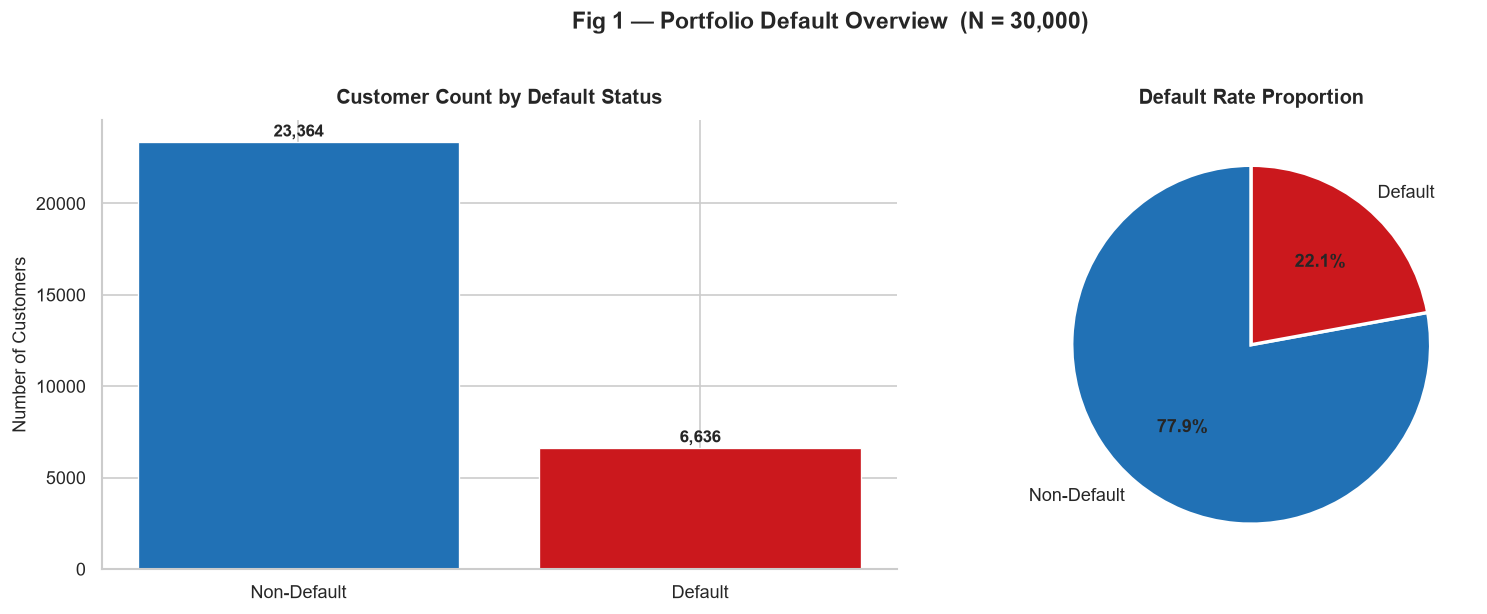

In [21]:
# ── Fig 1: Portfolio default overview ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=FIG_WIDE)

# Panel A: customer counts
counts = df[TARGET].value_counts().sort_index()
axes[0].bar(
    ['Non-Default', 'Default'],
    counts.values,
    color=CLR_PALETTE,
    edgecolor='white',
    linewidth=0.8,
)
for i, v in enumerate(counts.values):
    axes[0].text(
        i, v + 100, f'{v:,}',
        ha='center', va='bottom',
        fontsize=10, fontweight='bold',
    )
axes[0].set_title(
    'Customer Count by Default Status',
    fontsize=12, fontweight='bold', pad=10,
)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].set_xlabel('')

# Panel B: proportion pie chart
pie_vals = [100 - OVERALL_DR, OVERALL_DR]
pie_labels = ['Non-Default', 'Default']
_, _, autotexts = axes[1].pie(
    pie_vals,
    labels=pie_labels,
    colors=CLR_PALETTE,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
axes[1].set_title(
    'Default Rate Proportion',
    fontsize=12, fontweight='bold', pad=10,
)

fig.suptitle(
    'Fig 1 — Portfolio Default Overview  (N = 30,000)',
    fontsize=14, fontweight='bold', y=1.02,
)
plt.tight_layout()
plt.savefig(
    'figures/fig1_default_overview.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 1**  
The portfolio carries a **22.1 % default rate** (6,636 of 30,000 customers). This moderate class imbalance means any segment above 22 % is carrying above-average risk, and any segment well below it is relatively healthy. All subsequent segment comparisons are measured against this baseline.

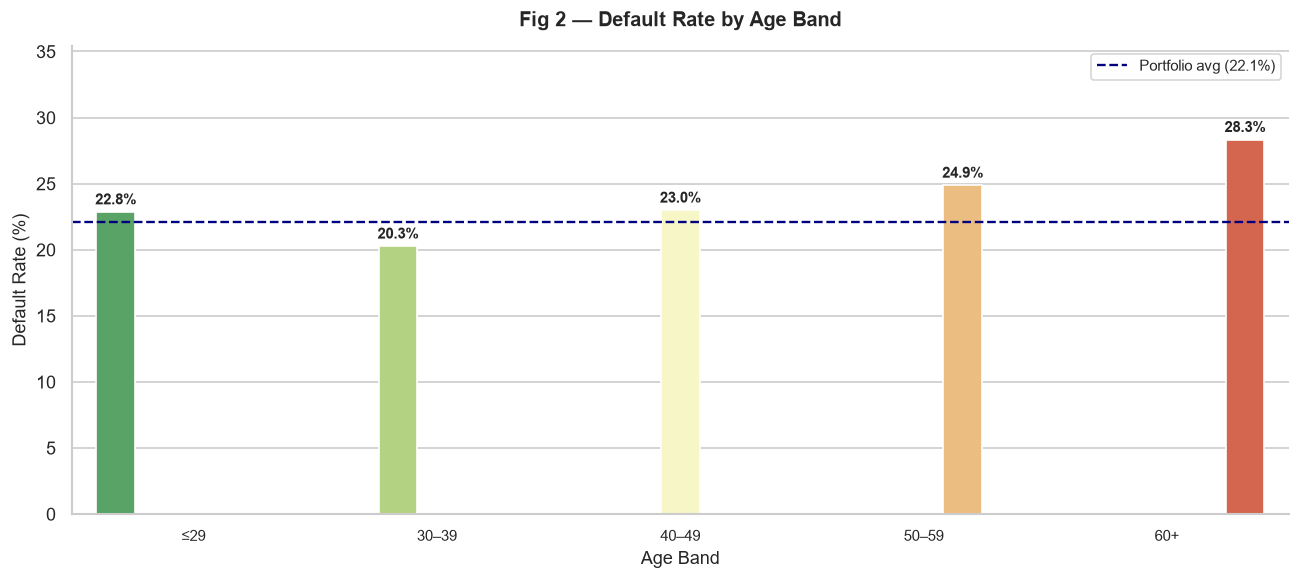

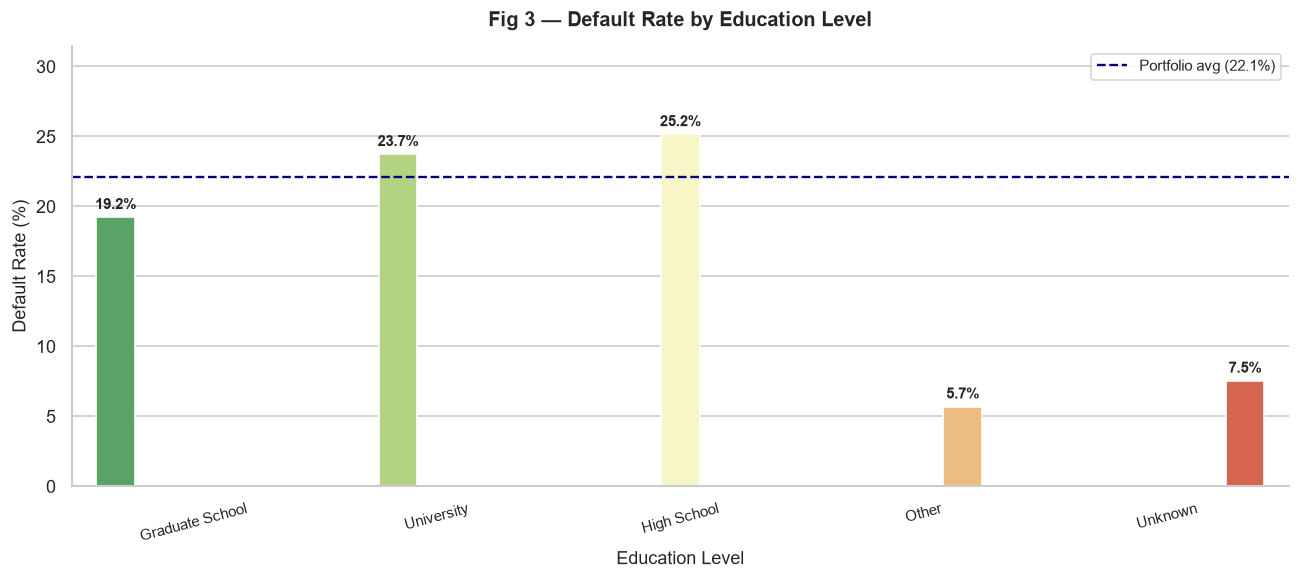

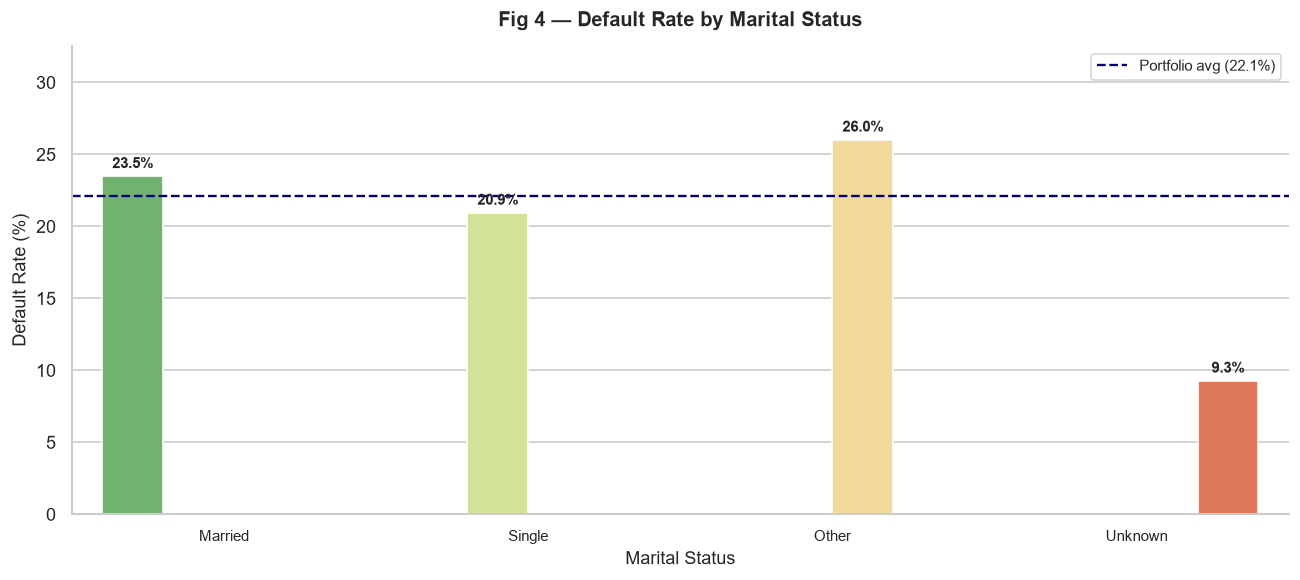

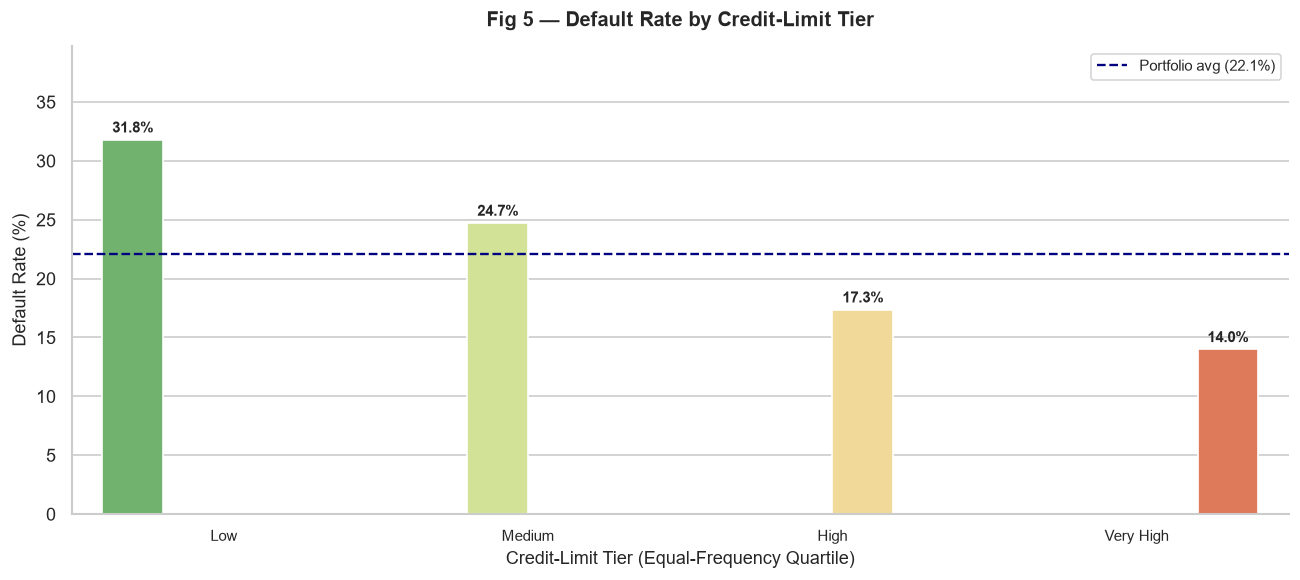

In [22]:
# ── Figs 2–5: Default rate by demographic group ───────────────────
# Config-driven loop keeps each chart consistent and DRY.
demo_configs = [
    {
        'col': 'age_group',
        'title': 'Fig 2 — Default Rate by Age Band',
        'xlabel': 'Age Band',
        'order': AGE_LABELS,
        'fname': 'fig2_age_band',
        'rotation': 0,
    },
    {
        'col': 'education',
        'title': 'Fig 3 — Default Rate by Education Level',
        'xlabel': 'Education Level',
        'order': [
            'Graduate School', 'University',
            'High School', 'Other', 'Unknown',
        ],
        'fname': 'fig3_education',
        'rotation': 15,
    },
    {
        'col': 'marriage',
        'title': 'Fig 4 — Default Rate by Marital Status',
        'xlabel': 'Marital Status',
        'order': ['Married', 'Single', 'Other', 'Unknown'],
        'fname': 'fig4_marriage',
        'rotation': 0,
    },
    {
        'col': 'credit_limit_tier',
        'title': 'Fig 5 — Default Rate by Credit-Limit Tier',
        'xlabel': 'Credit-Limit Tier (Equal-Frequency Quartile)',
        'order': TIER_LABELS,
        'fname': 'fig5_credit_limit_tier',
        'rotation': 0,
    },
]

for cfg in demo_configs:
    fig, ax = plt.subplots(figsize=FIG_SINGLE)
    plot_default_rate(
        df,
        group_col=cfg['col'],
        title=cfg['title'],
        xlabel=cfg['xlabel'],
        ax=ax,
        order=cfg['order'],
        x_rotation=cfg['rotation'],
    )
    plt.tight_layout()
    plt.savefig(
        f"figures/{cfg['fname']}_default_rate.png",
        dpi=150, bbox_inches='tight',
    )
    plt.show()


**Interpretation — Figs 2–5 (Descriptive Group Default Rates)**

- **Age (Fig 2):** The 60+ cohort has the highest observed default rate (28.3%), followed by the 50–59 group (24.9%). The 60+ group contains only 339 customers, so this estimate should be interpreted cautiously. The pattern is not monotonic across age bands; age is descriptive context rather than a basis for automated credit action.

- **Education (Fig 3):** High School has the highest observed rate among the documented groups (25.2%), followed by University (23.7%) and Graduate School (19.2%). The retained Other and Unknown codes have lower observed rates (5.7% and 7.5%); they remain in the data to preserve provenance, not because they indicate elevated risk.

- **Marital Status (Fig 4):** Married customers have a slightly higher observed rate than Single customers (23.5% versus 20.9%). Other is higher at 26.0%, while Unknown is lower at 9.3%; these are descriptive associations and do not establish household or causal effects.

- **Credit-Limit Tier (Fig 5):** Default rate decreases across the observed limit tiers, from 31.8% in Low to 14.0% in Very High. This is the strongest group contrast in these four charts, but credit-limit tier is an account characteristic rather than a demographic variable and may reflect prior issuer decisions or other confounding factors. It should not be interpreted causally.

---
## Section 2.2 — Repayment-Behaviour Analysis

Examines the six-month repayment-status history to identify which delay patterns most strongly predict default.

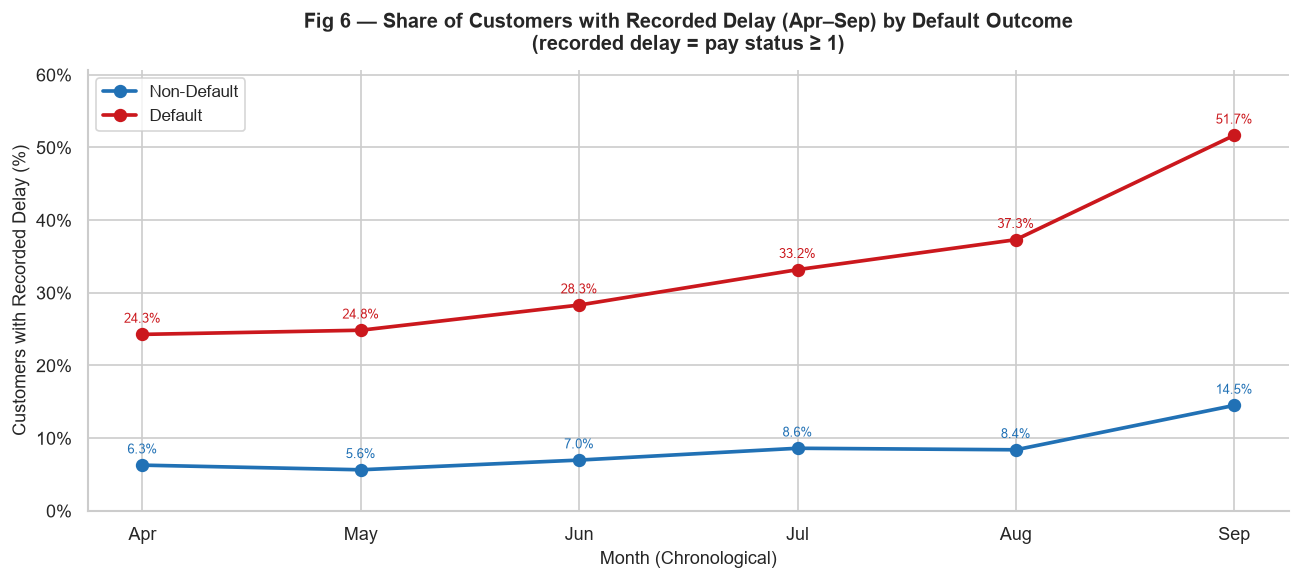

Recorded delay share by month and default outcome (%):
       Non-Default  Default
month                      
Apr           6.30    24.30
May           5.60    24.80
Jun           7.00    28.30
Jul           8.60    33.20
Aug           8.40    37.30
Sep          14.50    51.70


In [23]:
# ── Fig 6: Recorded payment-delay share over time ────────────────
# Plotted chronologically (Apr = oldest → Sep = most recent).
# A delay is defined consistently with num_delayed_months: status >= 1.
CHRONO_COLS = [f'pay_status_{i}' for i in range(6, 0, -1)]
MONTH_LABELS = ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep']

delay_flags = df[CHRONO_COLS].ge(1).assign(_target=df[TARGET])
delay_trend = (
    delay_flags.groupby('_target')[CHRONO_COLS]
    .mean()
    .mul(100)
    .T
)
delay_trend.columns = ['Non-Default', 'Default']
delay_trend['month'] = MONTH_LABELS

fig, ax = plt.subplots(figsize=FIG_SINGLE)

for label, colour in zip(
    ['Non-Default', 'Default'],
    CLR_PALETTE,
):
    ax.plot(
        delay_trend['month'],
        delay_trend[label],
        marker='o',
        markersize=7,
        linewidth=2.2,
        color=colour,
        label=label,
    )
    for month, value in zip(delay_trend['month'], delay_trend[label]):
        ax.annotate(
            f'{value:.1f}%',
            (month, value),
            xytext=(0, 7),
            textcoords='offset points',
            ha='center',
            fontsize=8,
            color=colour,
        )

ax.set_title(
    'Fig 6 — Share of Customers with Recorded Delay (Apr–Sep) '
    'by Default Outcome\n'
    '(recorded delay = pay status ≥ 1)',
    fontsize=12, fontweight='bold', pad=12,
)
ax.set_xlabel('Month (Chronological)', fontsize=11)
ax.set_ylabel('Customers with Recorded Delay (%)', fontsize=11)
ax.set_ylim(0, delay_trend[['Non-Default', 'Default']].to_numpy().max() + 9)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(
    'figures/fig6_pay_status_trend.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

print('Recorded delay share by month and default outcome (%):')
print(
    delay_trend.set_index('month')[['Non-Default', 'Default']]
    .round(1)
    .to_string()
)

**Interpretation — Fig 6**  
Customers who later default have a higher recorded-delay share in every month. The gap is 24.3% versus 6.3% in April and widens to 51.7% versus 14.5% in September, with generally greater separation in the more recent months. This chart measures the proportion with a recorded delay rather than averaging category codes such as −2, −1, and positive month counts. The pattern is a historical association, not evidence that delay alone causes default.

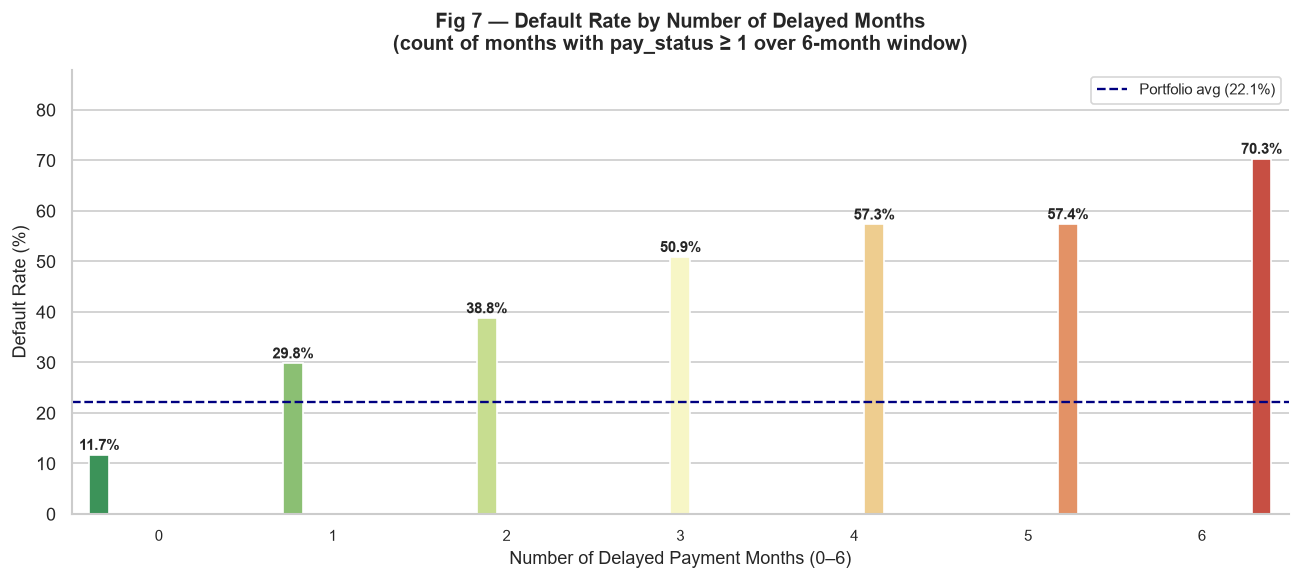

Default rate by number of delayed months:
                    default_rate      n
num_delayed_months                     
0                          11.70  19931
1                          29.80   4426
2                          38.80   1899
3                          50.90   1154
4                          57.30    951
5                          57.40    298
6                          70.30   1341


In [24]:
# ── Fig 7: Default rate by number of delayed months ─────────────────
fig, ax = plt.subplots(figsize=FIG_SINGLE)
plot_default_rate(
    df,
    group_col='num_delayed_months',
    title=(
        'Fig 7 — Default Rate by Number of Delayed Months\n'
        '(count of months with pay_status ≥ 1 over '
        '6-month window)'
    ),
    xlabel='Number of Delayed Payment Months (0–6)',
    ax=ax,
    order=list(range(7)),
)
plt.tight_layout()
plt.savefig(
    'figures/fig7_num_delayed_months.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

# Print supporting numbers
delay_dr = (
    df.groupby('num_delayed_months')[TARGET]
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'default_rate', 'count': 'n'})
)
delay_dr['default_rate'] = delay_dr['default_rate'].mul(100).round(1)
print('Default rate by number of delayed months:')
print(delay_dr.to_string())


**Interpretation — Fig 7**  
Default risk rises **near-monotonically** with the number of delayed months. Customers with zero recorded delays default at 11.7%, compared with 50.9% for three delayed months and 70.3% for all six months. Payment-delay frequency is therefore the strongest behavioural separator examined here and forms the primary dimension for the Phase 3 segmentation. These are observed portfolio rates, not causal or out-of-sample performance estimates.

---
## Section 2.3 — Financial Position Analysis

Compares bill amounts, payment amounts, pay-to-bill ratios, and balance trends between defaulting and non-defaulting customers.

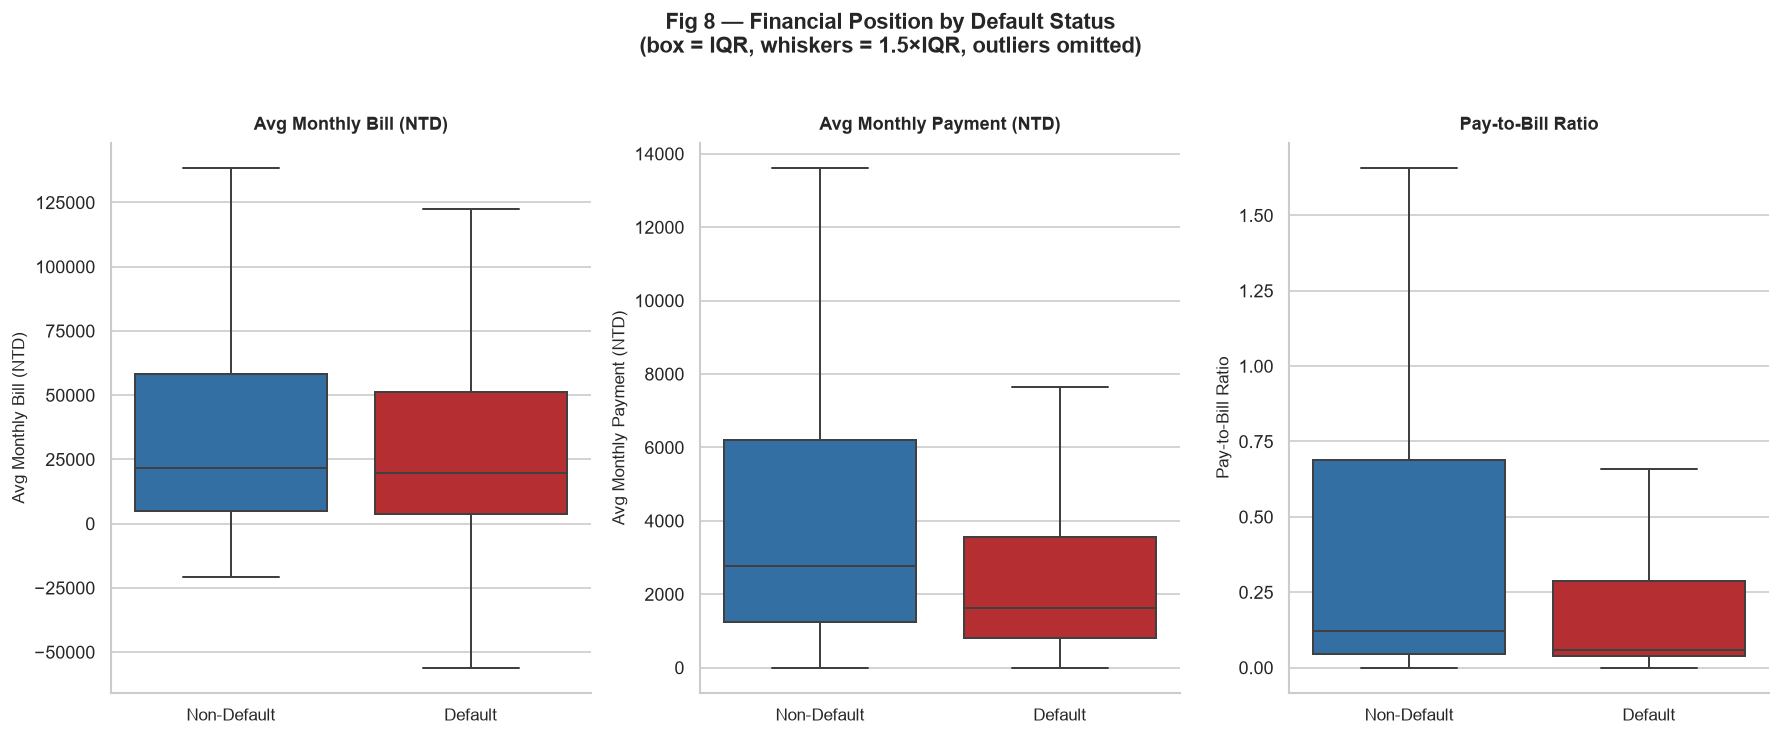

Median values by default status:
               avg_bill_amount  avg_pay_amount  pay_to_bill_ratio
default_label                                                    
Default              19,781.33        1,612.42               0.06
Non-Default          21,443.42        2,754.00               0.12


In [25]:
# ── Fig 8: Financial position — box plots ────────────────────────────
# showfliers=False omits individual outlier points for visual
# clarity; the IQR box and 1.5×IQR whiskers remain intact.
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

metrics = [
    ('avg_bill_amount',  'Avg Monthly Bill (NTD)'),
    ('avg_pay_amount',   'Avg Monthly Payment (NTD)'),
    ('pay_to_bill_ratio', 'Pay-to-Bill Ratio'),
]

for ax, (col, label) in zip(axes, metrics):
    sns.boxplot(
        data=df,
        x='default_label',
        y=col,
        hue='default_label',
        palette=CLR_PALETTE,
        order=['Non-Default', 'Default'],
        hue_order=['Non-Default', 'Default'],
        legend=False,
        showfliers=False,
        linewidth=1.2,
        ax=ax,
    )
    ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel('')
    ax.set_ylabel(label, fontsize=10)
    ax.tick_params(axis='x', labelsize=10)

fig.suptitle(
    'Fig 8 — Financial Position by Default Status\n'
    '(box = IQR, whiskers = 1.5×IQR, outliers omitted)',
    fontsize=13, fontweight='bold', y=1.02,
)
plt.tight_layout()
plt.savefig(
    'figures/fig8_financial_position_boxplots.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

# Median comparison table
print('Median values by default status:')
print(
    df.groupby('default_label')[
        ['avg_bill_amount', 'avg_pay_amount', 'pay_to_bill_ratio']
    ].median().round(2).to_string()
)


**Interpretation — Fig 8**  
Defaulting customers have a slightly **lower** median monthly bill than non-defaulters (NTD 19,781 versus NTD 21,443), but a much lower median monthly payment (NTD 1,612 versus NTD 2,754). Their median pay-to-bill ratio is also lower (6.0% versus 12.0%). The clearer group difference is therefore payment amount and bill coverage, not a higher typical bill balance. These are descriptive associations and do not by themselves establish financial stress as a cause of default.

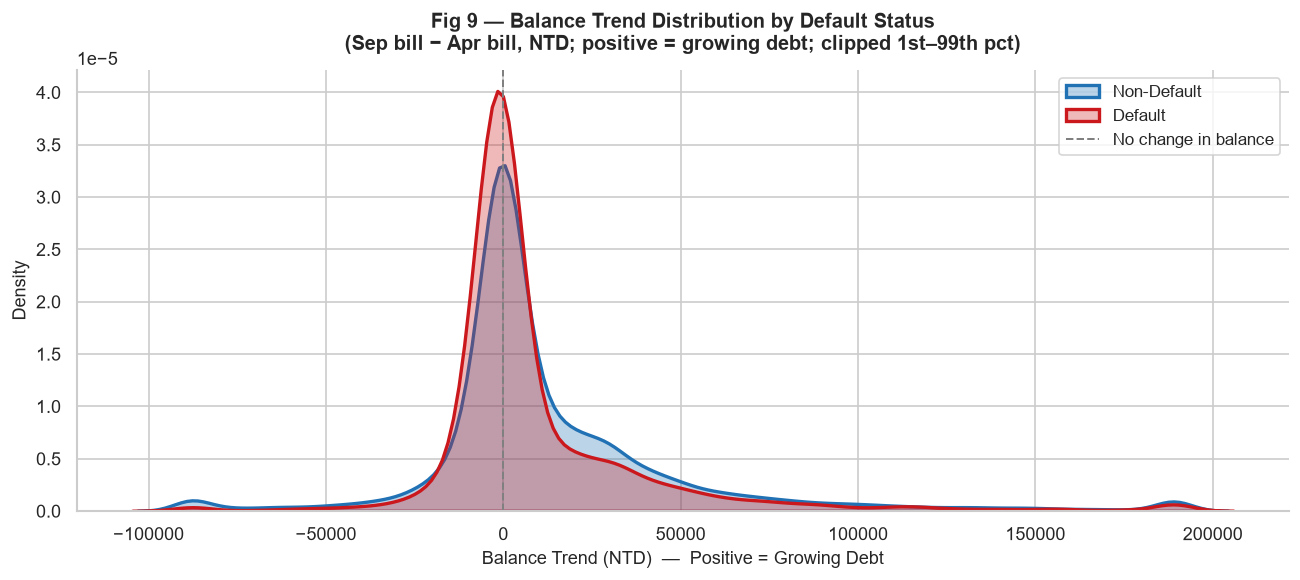

Median balance trend by default status:
default_label
Default            NTD 0
Non-Default    NTD 1,593


In [26]:
# ── Fig 9: Balance trend distribution (KDE) ─────────────────────────
# balance_trend = bill_amount_1 (Sep) − bill_amount_6 (Apr)
# Clipped to 1st–99th percentile to suppress extreme outliers.
p01 = df['balance_trend'].quantile(0.01)
p99 = df['balance_trend'].quantile(0.99)
df['balance_trend_clipped'] = df['balance_trend'].clip(p01, p99)

fig, ax = plt.subplots(figsize=FIG_SINGLE)

for label, colour in zip(
    ['Non-Default', 'Default'],
    CLR_PALETTE,
):
    subset = df.loc[
        df['default_label'] == label,
        'balance_trend_clipped',
    ]
    sns.kdeplot(
        data=subset,
        ax=ax,
        color=colour,
        fill=True,
        alpha=0.3,
        linewidth=2,
        label=label,
    )

# Zero line: balance unchanged from Apr to Sep
ax.axvline(
    0,
    color='grey',
    linestyle='--',
    linewidth=1.2,
    label='No change in balance',
)
ax.set_title(
    'Fig 9 — Balance Trend Distribution by Default Status\n'
    '(Sep bill − Apr bill, NTD; '
    'positive = growing debt; clipped 1st–99th pct)',
    fontsize=12, fontweight='bold', pad=12,
)
ax.set_xlabel(
    'Balance Trend (NTD)  —  Positive = Growing Debt',
    fontsize=11,
)
ax.set_ylabel('Density', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(
    'figures/fig9_balance_trend_kde.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

print('Median balance trend by default status:')
print(
    df.groupby('default_label')['balance_trend']
    .median()
    .apply(lambda x: f'NTD {x:,.0f}')
    .to_string()
)


**Interpretation — Fig 9**  
The two balance-trend distributions overlap heavily. The median trend is NTD 0 for defaulters and NTD 1,593 for non-defaulters; the corresponding means are approximately NTD 10,238 and NTD 12,952. This group comparison does not support a stronger positive balance trend among defaulters. Trajectory is retained as a secondary descriptive dimension in Phase 3, but Fig 9 does not justify treating it as a standalone early-warning signal.

---
## Section 2.4 — Relationship Analysis & Correlation Heatmap

Pearson correlations between engineered features and the default target reveal which variables carry the most predictive signal and how features relate to each other.

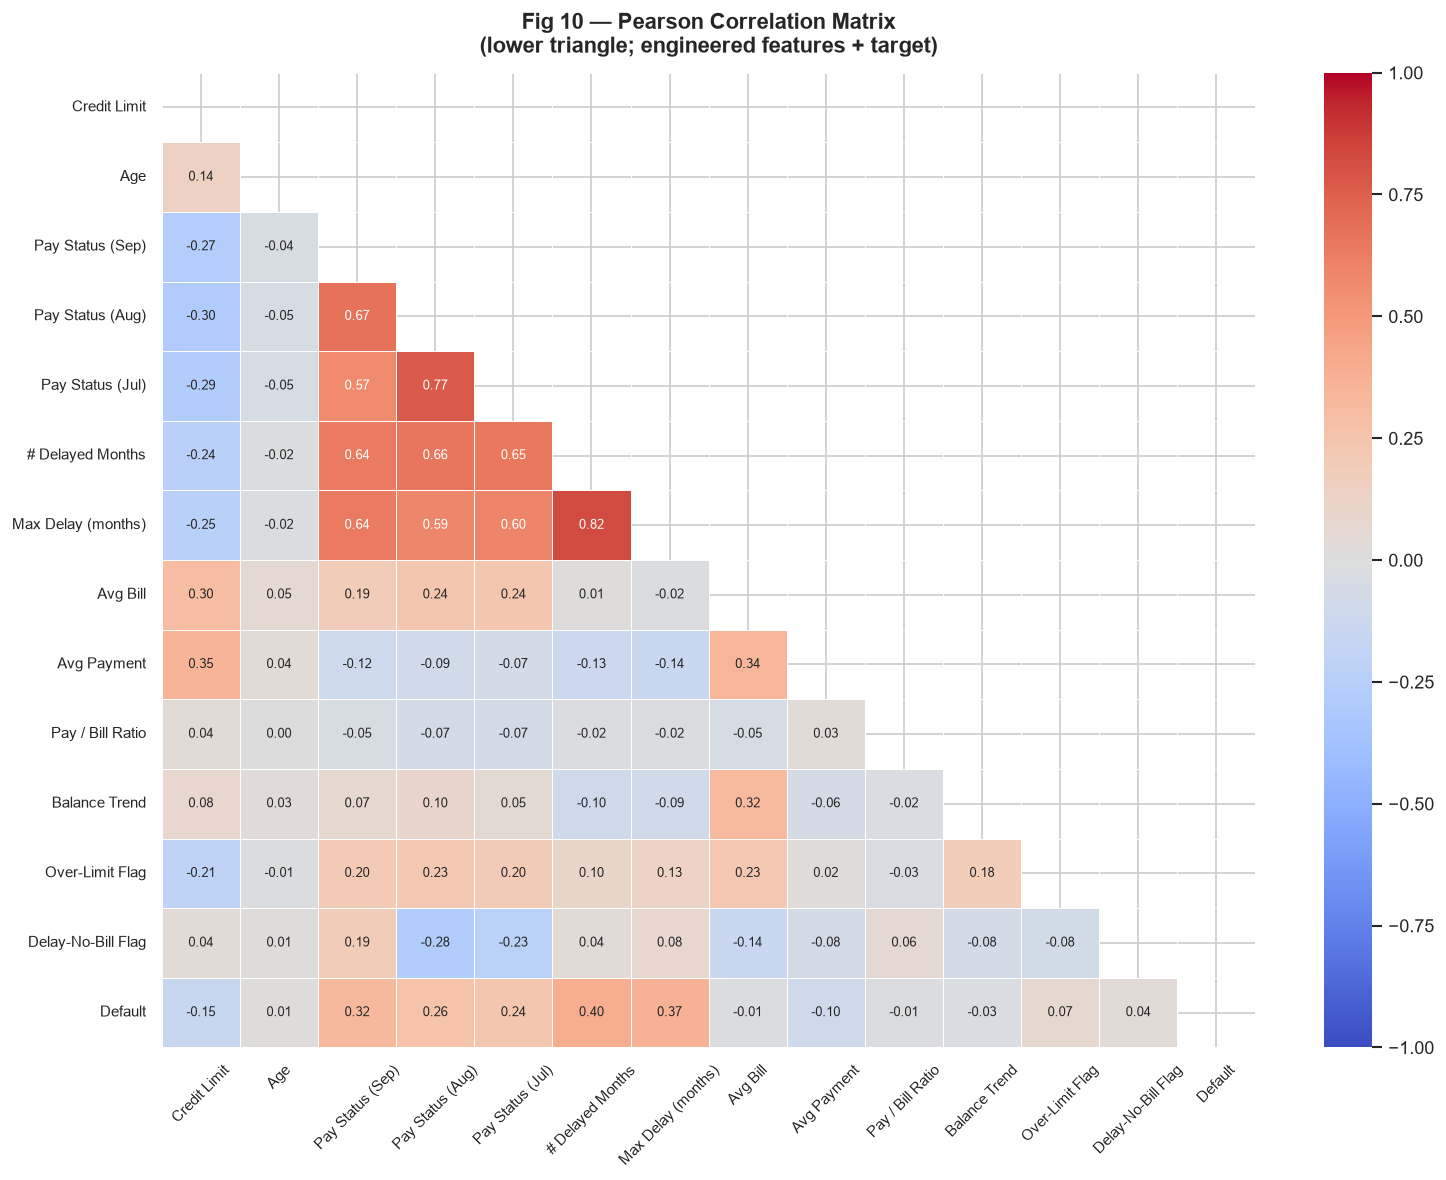

Top feature correlations with Default (absolute):
# Delayed Months     0.40
Max Delay (months)   0.37
Pay Status (Sep)     0.33
Pay Status (Aug)     0.26
Pay Status (Jul)     0.23
Credit Limit         0.15
Avg Payment          0.10
Over-Limit Flag      0.07
Delay-No-Bill Flag   0.04
Balance Trend        0.03
Age                  0.01
Pay / Bill Ratio     0.01
Avg Bill             0.01


In [27]:
# ── Fig 10: Pearson correlation heatmap ─────────────────────────────
# Uses engineered features rather than all 24 raw columns
# to produce a focused, readable matrix.
CORR_COLS = [
    'credit_limit',
    'age',
    'pay_status_1',
    'pay_status_2',
    'pay_status_3',
    'num_delayed_months',
    'max_delay_months',
    'avg_bill_amount',
    'avg_pay_amount',
    'pay_to_bill_ratio',
    'balance_trend',
    'flag_over_limit',
    'flag_delay_no_bill',
    TARGET,
]

CORR_LABELS = {
    'credit_limit':       'Credit Limit',
    'age':                'Age',
    'pay_status_1':       'Pay Status (Sep)',
    'pay_status_2':       'Pay Status (Aug)',
    'pay_status_3':       'Pay Status (Jul)',
    'num_delayed_months': '# Delayed Months',
    'max_delay_months':   'Max Delay (months)',
    'avg_bill_amount':    'Avg Bill',
    'avg_pay_amount':     'Avg Payment',
    'pay_to_bill_ratio':  'Pay / Bill Ratio',
    'balance_trend':      'Balance Trend',
    'flag_over_limit':    'Over-Limit Flag',
    'flag_delay_no_bill': 'Delay-No-Bill Flag',
    TARGET:               'Default',
}

corr = (
    df[CORR_COLS]
    .corr()
    .rename(index=CORR_LABELS, columns=CORR_LABELS)
)

# Lower-triangle mask (upper triangle redundant)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    annot_kws={'size': 8},
    ax=ax,
)
ax.set_title(
    'Fig 10 — Pearson Correlation Matrix\n'
    '(lower triangle; engineered features + target)',
    fontsize=13, fontweight='bold', pad=12,
)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)
plt.tight_layout()
plt.savefig(
    'figures/fig10_correlation_heatmap.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

# Top correlations with default target
default_corr = (
    corr['Default']
    .drop('Default')
    .abs()
    .sort_values(ascending=False)
)
print('Top feature correlations with Default (absolute):')
print(default_corr.round(3).to_string())


**Interpretation — Fig 10**  
The pay status variables — particularly September and August (`Pay Status (Sep)`, `Pay Status (Aug)`) — and the derived delay features (`# Delayed Months`, `Max Delay`) show the **strongest positive correlations with default**. The pay-to-bill ratio and credit limit correlate **negatively** with default: higher repayment capacity and higher credit limits are associated with lower risk.  

Age shows only a weak negative correlation, confirming that **behavioural features substantially outperform demographic attributes as default predictors** in this portfolio — a key justification for anchoring the Phase 3 segmentation on payment behaviour rather than demographics.

---
## Section 2.5 — Defaulter Archetype Analysis

The four analyses above each isolate a single lens — demographics, delay history, financial position, or correlation. This section synthesises them into **six mutually exclusive behavioural archetypes**, giving the board a single, intuitive map of *who* actually defaults and *why* — a descriptive bridge toward the formal risk-scoring framework built in Phase 3.

Each customer is assigned to exactly one archetype by a single reusable function evaluated in priority order, satisfying the rubric's emphasis on user-defined functions and advanced Pandas operations.

| # | Archetype | Rule |
|--:|:----------|:-----|
| 1 | Ghost / Dormant Fee Defaulters | 5 months with no activity, then a single late flag with zero bill |
| 2 | Severe Chronic Delinquents | 4–6 months delayed |
| 3 | Escalating Delinquents | 2–3 months delayed |
| 4 | Early-Stage Single Delay | Exactly 1 month delayed |
| 5 | High-Utilisation Silent Risk | 0 months delayed, utilisation ≥ 80% |
| 6 | No-Warning-Signal (Invisible) Defaulters | 0 months delayed, utilisation < 80% |


In [28]:
# ── `credit_utilization` was recreated in the shared setup cell ───
# ── Constants for the classification rules ───────────────────────
GHOST_DELAY_CODE = 1
GHOST_INACTIVE_CODE = -2
SEVERE_DELAY_MIN_MONTHS = 4
ESCALATING_DELAY_MIN_MONTHS = 2
HIGH_UTILISATION_THRESHOLD = 0.80

# ── Strict ghost-account flag ─────────────────────────────────────
# Stricter than Phase 1's flag_delay_no_bill: requires the FULL
# 5-month inactivity pattern (-2) in addition to a zero balance,
# isolating the true dormant-fee subset (495 of 1,312 flagged
# rows).
df['is_ghost_account'] = (
    (df['pay_status_1'] == GHOST_DELAY_CODE)
    & df[BILL_AMOUNT_COLS].eq(0).all(axis=1)
    & df[PAY_AMOUNT_COLS].eq(0).all(axis=1)
    & df[
        ['pay_status_2', 'pay_status_3', 'pay_status_4',
         'pay_status_5', 'pay_status_6']
    ].eq(GHOST_INACTIVE_CODE).all(axis=1)
)


def classify_defaulter_archetype(row: pd.Series) -> str:
    """Assign one of six mutually exclusive behavioural archetypes.

    Rules are evaluated in priority order; the first match wins,
    guaranteeing every customer receives exactly one label.

    Parameters
    ----------
    row : pd.Series
        A customer record containing 'is_ghost_account',
        'num_delayed_months', and 'credit_utilization'.

    Returns
    -------
    str
        One of six archetype labels.
    """
    if row['is_ghost_account']:
        return '1. Ghost / Dormant Fee Defaulters'
    if row['num_delayed_months'] >= SEVERE_DELAY_MIN_MONTHS:
        return '2. Severe Chronic Delinquents'
    if row['num_delayed_months'] >= ESCALATING_DELAY_MIN_MONTHS:
        return '3. Escalating Delinquents'
    if row['num_delayed_months'] == 1:
        return '4. Early-Stage Single Delay'
    if row['credit_utilization'] >= HIGH_UTILISATION_THRESHOLD:
        return '5. High-Utilisation Silent Risk'
    return '6. No-Warning-Signal (Invisible) Defaulters'


df['defaulter_archetype'] = df.apply(
    classify_defaulter_archetype, axis=1
)

# ── Exhaustiveness checks ─────────────────────────────────────────
assert df['defaulter_archetype'].notna().all(), (
    "Every customer must receive an archetype label."
)
assert df['defaulter_archetype'].nunique() == 6, (
    "Expected exactly 6 distinct archetypes."
)

print('Archetype classification applied ✓')
print(df['defaulter_archetype'].value_counts().sort_index())


Archetype classification applied ✓
defaulter_archetype
1. Ghost / Dormant Fee Defaulters                495
2. Severe Chronic Delinquents                   2590
3. Escalating Delinquents                       3053
4. Early-Stage Single Delay                     3931
5. High-Utilisation Silent Risk                 2605
6. No-Warning-Signal (Invisible) Defaulters    17326
Name: count, dtype: int64


In [29]:
# ── Archetype summary: size, default rate, risk concentration ───
archetype_summary = df.groupby('defaulter_archetype').agg(
    total_customers=('customer_id', 'count'),
    defaulters=(TARGET, 'sum'),
    avg_age=('age', 'mean'),
    avg_credit_limit=('credit_limit', 'mean'),
    avg_credit_utilization=('credit_utilization', 'mean'),
)

archetype_summary['default_rate_pct'] = (
    archetype_summary['defaulters']
    / archetype_summary['total_customers']
    * 100
)
total_defaulters = df[TARGET].sum()
archetype_summary['pct_of_all_defaulters'] = (
    archetype_summary['defaulters'] / total_defaulters * 100
)
archetype_summary['pct_of_portfolio'] = (
    archetype_summary['total_customers'] / len(df) * 100
)

archetype_summary = archetype_summary[[
    'total_customers', 'pct_of_portfolio', 'defaulters',
    'default_rate_pct', 'pct_of_all_defaulters',
    'avg_age', 'avg_credit_limit', 'avg_credit_utilization',
]].round(1)

assert archetype_summary['defaulters'].sum() == total_defaulters, (
    "Archetype split must reconcile to total defaulters."
)
archetype_summary


,total_customers,pct_of_portfolio,defaulters,default_rate_pct,pct_of_all_defaulters,avg_age,avg_credit_limit,avg_credit_utilization
defaulter_archetype,,,,,,,,
1. Ghost / Dormant Fee Defaulters,495,1.60,196,39.60,3.00,36.90,"202,040.40",0.00
2. Severe Chronic Delinquents,2590,8.60,1659,64.10,25.00,35.20,"91,532.80",0.60
3. Escalating Delinquents,3053,10.20,1323,43.30,19.90,35.00,"116,005.90",0.50
4. Early-Stage Single Delay,3931,13.10,1124,28.60,16.90,35.20,"152,891.40",0.30
5. High-Utilisation Silent Risk,2605,8.70,383,14.70,5.80,35.50,"119,108.50",0.90
6. No-Warning-Signal (Invisible) Defaulters,17326,57.80,1951,11.30,29.40,35.60,"197,506.10",0.30


**Interpretation — Archetype Summary**  
The standout result: the **No-Warning-Signal** archetype is 57.8% of the entire portfolio, and within it, 1,951 customers still defaulted — **29.4% of every default in the dataset**, the single largest contributor of any archetype. Their average utilisation (0.3) and credit limit (NTD 197,506) are statistically indistinguishable from the broader non-defaulting population. No combination of the six months of payment history captured here flags them in advance.  

By contrast, **Severe Chronic Delinquents** are easy to spot (64.1% default rate) but represent only 25.0% of total defaults — fewer in absolute terms than the invisible group. **Catching the obvious cases alone is not enough to materially reduce portfolio losses.**

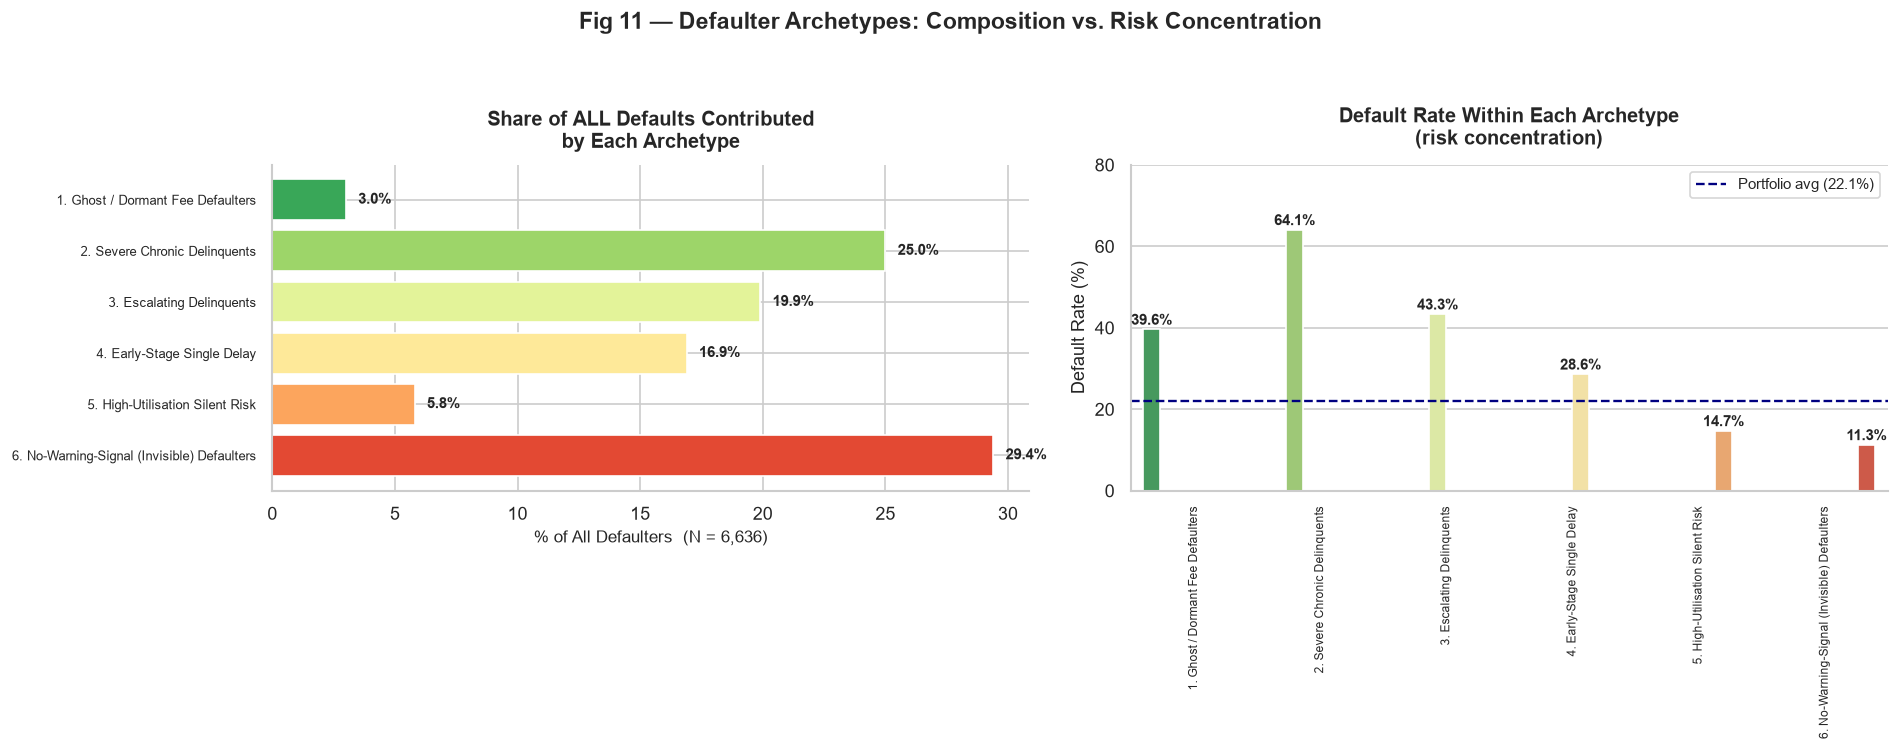

In [30]:
# ── Fig 11: Archetype composition vs. risk concentration ────────
ARCHETYPE_ORDER = sorted(df['defaulter_archetype'].unique())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A — composition: share of ALL defaults per archetype
composition = archetype_summary['pct_of_all_defaulters'].reindex(
    ARCHETYPE_ORDER
)
bar_colours = sns.color_palette('RdYlGn_r', len(composition))
bars = axes[0].barh(
    composition.index,
    composition.values,
    color=bar_colours,
    edgecolor='white',
)
for bar, value in zip(bars, composition.values):
    axes[0].text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.1f}%',
        va='center',
        fontsize=9,
        fontweight='bold',
    )
axes[0].set_title(
    'Share of ALL Defaults Contributed\nby Each Archetype',
    fontsize=12, fontweight='bold', pad=10,
)
axes[0].set_xlabel(
    '% of All Defaulters  (N = 6,636)', fontsize=10
)
axes[0].invert_yaxis()
axes[0].tick_params(axis='y', labelsize=8)

# Panel B — risk concentration: default rate within each archetype
plot_default_rate(
    df,
    group_col='defaulter_archetype',
    title='Default Rate Within Each Archetype\n(risk concentration)',
    xlabel='',
    ax=axes[1],
    order=ARCHETYPE_ORDER,
    x_rotation=90,
)
axes[1].tick_params(axis='x', labelsize=7)

fig.suptitle(
    'Fig 11 — Defaulter Archetypes: '
    'Composition vs. Risk Concentration',
    fontsize=14, fontweight='bold', y=1.04,
)
plt.tight_layout()
plt.savefig(
    'figures/fig11_defaulter_archetypes.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 11**  
The left panel makes the composition finding visible at a glance: the Invisible archetype's bar is the longest in the chart, confirming it as the leading single source of default volume. The right panel shows the opposite ranking — its *per-customer* risk (11.3%) is the lowest of the six. **Size, not individual risk, is what makes this group matter**, and it is the clearest argument in the dataset for enriching the model with external, non-behavioural data in Phase 5.

In [31]:
# ── One real defaulter example per archetype (reproducible) ─────
# Sorted by customer_id so the same example is returned on every
# run, keeping the notebook fully reproducible.
example_defaulters = (
    df[df[TARGET] == 1]
    .sort_values('customer_id')
    .groupby('defaulter_archetype', sort=False)
    .head(1)
)

EXAMPLE_COLS = [
    'customer_id', 'age', 'credit_limit',
    'pay_status_1', 'pay_status_2', 'pay_status_3',
    'pay_status_4', 'pay_status_5', 'pay_status_6',
    'avg_bill_amount', 'avg_pay_amount', 'credit_utilization',
    'num_delayed_months',
]

(
    example_defaulters
    .set_index('defaulter_archetype')[EXAMPLE_COLS]
    .sort_index()
)


,customer_id,age,credit_limit,pay_status_1,pay_status_2,pay_status_3,pay_status_4,pay_status_5,pay_status_6,avg_bill_amount,avg_pay_amount,credit_utilization,num_delayed_months
defaulter_archetype,,,,,,,,,,,,,
1. Ghost / Dormant Fee Defaulters,80,44,240000,1,-2,-2,-2,-2,-2,0.00,0.00,0.00,1
2. Severe Chronic Delinquents,14,30,70000,1,2,2,0,0,2,"56,447.50","1,783.33",0.81,4
3. Escalating Delinquents,1,24,20000,2,2,-1,-1,-2,-2,"1,284.00",114.83,0.06,2
4. Early-Stage Single Delay,27,27,60000,1,-2,-1,-1,-1,-1,-65.67,416.67,0.00,1
5. High-Utilisation Silent Risk,79,22,30000,0,0,0,0,0,0,"24,864.33","1,401.83",0.83,0
6. No-Warning-Signal (Invisible) Defaulters,22,39,120000,-1,-1,-1,-1,-1,-1,316.00,263.33,0.00,0


**Interpretation — Example Defaulters**  
Customer **#22** (Invisible archetype) paid in full for six consecutive months — `pay_status` of −1 throughout — on a tiny ~NTD 316 average bill, then defaulted regardless. Customer **#79** (High-Utilisation Silent Risk) shows the opposite shape: also zero delays, but running at 83% of their credit limit every month. Customer **#14** (Severe Chronic) is the conventional case: four months of delay against a bill close to their credit ceiling.  

These three real records justify treating **delinquency** and **utilisation** as separate scoring dimensions rather than one blended score — exactly the dimension structure specified for the Phase 3 risk framework.

---
## Phase 2 Summary

| # | Question | Key Finding |
|--:|:---------|:------------|
| 1 | Overall default rate | **22.1%** (6,636 / 30,000 customers) |
| 2 | Strongest descriptive group contrast | **Credit-limit tier** — Low is 31.8% versus 14.0% for Very High; this is not a demographic or causal effect |
| 3 | Strongest behavioural signal examined | **Number of delayed months** — 0 delays → 11.7%; 3 delays → 50.9%; 6 delays → 70.3% |
| 4 | Financial position | Defaulters have slightly lower median bills but much lower median payments and bill coverage; balance trend is not a strong group separator |
| 5 | Feature correlations | Pay status and delay features dominate; demographics add limited predictive value |
| 6 | Defaulter archetypes | **29.4% of all defaults** come from customers with zero recorded payment delays — a key data limitation for Phase 3 |

**Responsible interpretation:** demographic patterns are descriptive portfolio context only. Phase 3 prioritises repayment behaviour, utilisation, and balance trajectory; age, sex, education, and marital status must not be used as automatic adverse-action rules.  

**11 visualisations produced** (Figs 1–11), each saved to `figures/`.  
**Proceed to Phase 3 — Credit-Risk Segmentation.**

# Phase 3 - Credit Risk Segmentation

Apply the transparent four-dimension framework, validate segment default rates against observed outcomes, and explain which behaviours drive each segment.

## Imports and Setup

In [32]:
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

# ── Display preferences ───────────────────────────────────────────
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
os.makedirs('figures', exist_ok=True)
print("Libraries loaded ✓")


Libraries loaded ✓


## Constants

All scoring thresholds and segment boundaries are defined here as named constants (PEP 8: `UPPER_CASE`). Centralising them means any recalibration only requires editing this single cell.

In [33]:
# ── File path ────────────────────────────────────────────────────
CLEANED_PATH = "cleaned_credit_data.csv"

# ── Column groups ────────────────────────────────────────────────
PAY_STATUS_COLS = [f'pay_status_{i}' for i in range(1, 7)]
BILL_AMOUNT_COLS = [f'bill_amount_{i}' for i in range(1, 7)]
PAY_AMOUNT_COLS = [f'pay_amount_{i}' for i in range(1, 7)]
TARGET = 'default_next_month'

# ── Ghost-account detection constants ────────────────────────────
GHOST_RECENT_STATUS = 1    # pay_status_1 = 1 (one-month delay)
GHOST_INACTIVE_CODE = -2   # undocumented code: no consumption

# ── Delinquency scoring bins (fixed rules, not qcut) ─────────────
# Justified: num_delayed_months is heavily right-skewed (~66% of
# customers have 0 delays), making quintile bins uninformative.
DELINQUENCY_BINS = [-1, 0, 1, 2, 4, 6]
DELINQUENCY_LABELS = [1, 2, 3, 4, 5]

# ── Repayment capacity scoring ────────────────────────────────────
# qcut into 5 quintiles, REVERSED (high ratio = low score = safe)
REPAYMENT_QUINTILES = 5
REPAYMENT_LABELS = [5, 4, 3, 2, 1]  # reversed
REPAYMENT_NAN_SCORE = 3             # neutral score for NaN ratios

# ── Exposure scoring ──────────────────────────────────────────────
EXPOSURE_QUINTILES = 5
EXPOSURE_LABELS = [1, 2, 3, 4, 5]  # high utilization = score 5

# ── Trajectory scoring ────────────────────────────────────────────
TRAJECTORY_QUINTILES = 5
TRAJECTORY_LABELS = [1, 2, 3, 4, 5]  # growing debt = score 5

# ── Delinquency weight ────────────────────────────────────────────
# Phase 2 correlation analysis (Fig 10) confirmed delinquency is
# the strongest single predictor. Weight of 2 prevents the three
# secondary dimensions from masking a clear delay pattern.
DELINQUENCY_WEIGHT = 2
SECONDARY_WEIGHT = 1  # repayment, exposure, trajectory

# ── Combined score range ──────────────────────────────────────────
# Min: 2*1 + 1 + 1 + 1 = 5
# Max: 2*5 + 5 + 5 + 5 = 25
SCORE_MIN = 5
SCORE_MAX = 25

# ── Segment thresholds ────────────────────────────────────────────
SEGMENT_BINS = [4, 9, 14, 19, 25]
SEGMENT_LABELS = ['Healthy', 'Watchlist', 'At-Risk', 'Critical']
SEGMENT_ORDER = ['Healthy', 'Watchlist', 'At-Risk', 'Critical']

# ── Colour map ────────────────────────────────────────────────────
SEGMENT_COLOURS = {
    'Healthy':   '#2ca25f',
    'Watchlist': '#feb24c',
    'At-Risk':   '#f03b20',
    'Critical':  '#7a0177',
}

print("Constants defined ✓")
print(
    f'  Score range : {SCORE_MIN}–{SCORE_MAX}\n'
    f'  Segments    : {", ".join(SEGMENT_LABELS)}'
)


Constants defined ✓
  Score range : 5–25
  Segments    : Healthy, Watchlist, At-Risk, Critical


---
## Load Data and Recompute Derived Columns

Phase 3 loads the stable 34-column dataset produced by Phase 1. Phase-specific reporting fields are deliberately recreated: this notebook uses the same `credit_utilization = avg_bill_amount / credit_limit`, clipped at zero, as Phases 2 and 4. `age_group` and `credit_limit_tier` are Phase 2 EDA fields and are not needed for behavioural scoring. `is_ghost_account` is also recomputed from saved activity columns.

In [34]:
df = pd.read_csv(CLEANED_PATH)

assert df.shape == (30_000, 34), (
    f'Unexpected shape {df.shape}; expected (30000, 34).'
)

# ── Credit utilisation (shared Phase 2-4 definition) ─────────────
# Clipped at 0 so credit-balance customers (negative avg bill)
# register as 0% utilisation rather than a negative value.
df['credit_utilization'] = (
    df['avg_bill_amount'] / df['credit_limit']
).clip(lower=0)

# ── Ghost-account flag ────────────────────────────────────────────
# Stricter than Phase 1's flag_delay_no_bill:
# Requires the FULL 5-month inactivity pattern in PAY_2-6
# to isolate the dormant-fee subset (495 rows, 39.6% default rate)
# from the broader 1,312-row delay-no-bill group.
df['is_ghost_account'] = (
    (df['pay_status_1'] == GHOST_RECENT_STATUS)
    & df[BILL_AMOUNT_COLS].eq(0).all(axis=1)
    & df[PAY_AMOUNT_COLS].eq(0).all(axis=1)
    & df[
        ['pay_status_2', 'pay_status_3', 'pay_status_4',
         'pay_status_5', 'pay_status_6']
    ].eq(GHOST_INACTIVE_CODE).all(axis=1)
)

OVERALL_DR = df[TARGET].mean() * 100

print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} cols")
print(f"Ghost accounts identified: {df['is_ghost_account'].sum():,}")
print(f"Overall default rate: {OVERALL_DR:.2f}%")


Dataset loaded: 30,000 rows x 36 cols
Ghost accounts identified: 495
Overall default rate: 22.12%


## Reusable Visualisation Helper

Redefined here so Phase 3 runs as a standalone notebook without depending on Phase 2 being executed first.

In [35]:
def plot_default_rate(
    data: pd.DataFrame,
    group_col: str,
    title: str,
    xlabel: str,
    ax: plt.Axes,
    order: list = None,
    palette: dict = None,
) -> None:
    """Bar chart of default rate (%) per category.

    Draws a dashed reference line at the portfolio-wide default
    rate and annotates each bar with its percentage value.

    Parameters
    ----------
    data : pd.DataFrame
        Must contain group_col and TARGET columns.
    group_col : str
        Categorical column to group by.
    title, xlabel : str
        Chart title and x-axis label.
    ax : plt.Axes
        Target Axes object.
    order : list, optional
        Explicit category order for the x-axis.
    palette : dict, optional
        Mapping of category label to colour.
    """
    rates = (
        data.groupby(group_col, observed=True)[TARGET]
        .mean().mul(100)
        .reset_index(name='default_rate')
    )
    if order is not None:
        rates[group_col] = pd.Categorical(
            rates[group_col], categories=order, ordered=True
        )
        rates = rates.sort_values(group_col)

    _palette = (
        [palette[lbl] for lbl in rates[group_col]]
        if palette else None
    )
    sns.barplot(
        data=rates, x=group_col, y='default_rate',
        hue=group_col,
        palette=_palette or 'RdYlGn_r',
        order=order, legend=False, ax=ax,
    )
    ax.axhline(
        OVERALL_DR, color='navy', linestyle='--',
        linewidth=1.4,
        label=f'Portfolio avg ({OVERALL_DR:.1f}%)',
    )
    for patch in ax.patches:
        h = patch.get_height()
        if np.isnan(h) or h == 0:
            continue
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            h + 0.5, f'{h:.1f}%',
            ha='center', va='bottom',
            fontsize=10, fontweight='bold',
        )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Default Rate (%)', fontsize=11)
    ax.set_ylim(0, rates['default_rate'].max() * 1.3)
    ax.legend(fontsize=9)


print("Helper defined ✓")


Helper defined ✓


---
## Section 3.1 — Four Scoring Dimension Functions

Each dimension is implemented as a vectorised function that accepts a `pd.Series` and returns a scored `pd.Series`. Vectorised operations are preferred over row-wise `.apply()` for performance and readability.

All functions include:
- A docstring with the scoring rationale
- Direction notes (worse behaviour → higher score)
- Edge-case handling
- Post-call distribution print to confirm no silent failures

**Why the scoring methods differ:** delinquency uses fixed business-friendly rules because its distribution is dominated by zero-delay customers. Repayment capacity, credit utilisation, and balance trajectory use `qcut` quintiles because they are continuous measures where relative position within this portfolio is useful. These quintile scores are transparent portfolio rankings, not universal lending thresholds; the fixed Phase 4 intervention thresholds are kept separate.

For repayment capacity, the 1,071 undefined `pay_to_bill_ratio` values are excluded from the quintile calculation and assigned the neutral score of 3 afterwards. This avoids treating a zero or negative bill as either unusually safe or unusually risky, and no ratio value is imputed.


### Dimension 1 — Delinquency

Measures how often a customer paid late over the 6-month window.
Fixed rules replace `qcut` here because `num_delayed_months` is **heavily right-skewed** — 66% of customers have 0 delays. Quintile bins on this distribution would collapse most of the at-risk population into a single bucket.

In [36]:
def score_delinquency(num_delayed_months: pd.Series) -> pd.Series:
    """Score payment delinquency using fixed rule-based bins.

    Fixed-rule scoring is used instead of qcut because
    num_delayed_months is heavily right-skewed (~66% zeros),
    which would cause quintile bins to lose resolution on the
    high-risk tail that matters most.

    Scoring rules (worse behaviour = higher score):
        0 delayed months → 1  (no delinquency)
        1 delayed month  → 2  (isolated incident)
        2 delayed months → 3  (recurring)
        3–4 months       → 4  (sustained pattern)
        5–6 months       → 5  (severe, full-window delinquency)

    Parameters
    ----------
    num_delayed_months : pd.Series
        Count of months with pay_status >= 1 (integer, range 0-6).

    Returns
    -------
    pd.Series of int
        Delinquency scores in range [1, 5].
    """
    return pd.cut(
        num_delayed_months,
        bins=DELINQUENCY_BINS,
        labels=DELINQUENCY_LABELS,
        right=True,
    ).astype(int)


df['delinquency_score'] = score_delinquency(
    df['num_delayed_months']
)

assert df['delinquency_score'].between(1, 5).all(), (
    "Delinquency scores must be in [1, 5]."
)

print("Delinquency score distribution:")
print(df['delinquency_score'].value_counts().sort_index())


Delinquency score distribution:
delinquency_score
1    19931
2     4426
3     1899
4     2105
5     1639
Name: count, dtype: int64


### Dimension 2 — Repayment Capacity

Measures how much of the monthly bill a customer actually pays back. Direction is **reversed**: a higher pay-to-bill ratio means the customer is safer, so they receive a lower score.

For 1,071 customers, `pay_to_bill_ratio` is `NaN` because the average bill is zero or negative. This group includes no-bill/dormant patterns and credit-balance patterns, so repayment capacity is undefined. These rows receive the neutral score of **3**; this condition is distinct from the separate `flag_credit_balance` indicator, which records any negative bill month.

In [37]:
def score_repayment_capacity(
    pay_to_bill_ratio: pd.Series,
) -> pd.Series:
    """Score repayment capacity from the pay-to-bill ratio.

    Scoring uses quintile-based bins (qcut) and is REVERSED:
    customers who pay a larger fraction of their bill are safer
    and therefore receive a lower risk score.

    NaN values arise when avg_bill_amount <= 0. These accounts
    cannot be meaningfully scored on this ratio and receive the
    neutral mid-point score of 3.

    Parameters
    ----------
    pay_to_bill_ratio : pd.Series
        Ratio of avg monthly payment to avg monthly bill.
        May contain NaN for zero/negative-average-bill accounts.

    Returns
    -------
    pd.Series of int
        Repayment capacity scores in range [1, 5].
        NaN inputs → neutral score 3.
    """
    raw = pd.qcut(
        pay_to_bill_ratio,
        q=REPAYMENT_QUINTILES,
        labels=REPAYMENT_LABELS,  # reversed: high ratio → score 1
        duplicates='drop',
    )
    # Undefined-ratio rows receive the neutral score.
    return raw.astype(float).fillna(REPAYMENT_NAN_SCORE).astype(int)


df['repayment_score'] = score_repayment_capacity(
    df['pay_to_bill_ratio']
)

assert df['repayment_score'].between(1, 5).all(), (
    "Repayment scores must be in [1, 5]."
)

nan_filled = df['pay_to_bill_ratio'].isna().sum()
print(f"Repayment score distribution (NaN → 3 for {nan_filled} rows):")
print(df['repayment_score'].value_counts().sort_index())

Repayment score distribution (NaN → 3 for 1071 rows):
repayment_score
1    5786
2    5786
3    6856
4    5786
5    5786
Name: count, dtype: int64


### Dimension 3 — Exposure

Measures how much of the credit limit the customer is using on average. A customer who is consistently near their credit ceiling has higher financial exposure and less buffer to absorb an income shock.

In [38]:
def score_exposure(credit_utilization: pd.Series) -> pd.Series:
    """Score credit exposure from the utilisation ratio.

    Utilisation = avg_bill_amount / credit_limit, clipped at 0.
    Higher utilisation signals the customer has less financial
    buffer and is more exposed to income shocks.

    Uses qcut for equal-frequency quintile bins since utilisation
    is a well-distributed continuous variable.

    Parameters
    ----------
    credit_utilization : pd.Series
        avg_bill_amount / credit_limit, clipped at 0.

    Returns
    -------
    pd.Series of int
        Exposure scores in range [1, 5].
    """
    return pd.qcut(
        credit_utilization,
        q=EXPOSURE_QUINTILES,
        labels=EXPOSURE_LABELS,  # high utilization → score 5
        duplicates='drop',
    ).astype(int)


df['exposure_score'] = score_exposure(df['credit_utilization'])

assert df['exposure_score'].between(1, 5).all(), (
    "Exposure scores must be in [1, 5]."
)

print("Exposure score distribution:")
print(df['exposure_score'].value_counts().sort_index())
print(f"\nAvg credit utilization by score:")
print(
    df.groupby('exposure_score')['credit_utilization']
    .mean().apply(lambda x: f'{x:.1%}').to_string()
)


Exposure score distribution:
exposure_score
1    6000
2    6000
3    6000
4    6000
5    6000
Name: count, dtype: int64

Avg credit utilization by score:
exposure_score
1     0.6%
2     5.9%
3    28.6%
4    61.0%
5    90.5%


### Dimension 4 — Trajectory

Measures whether a customer's outstanding debt is growing or shrinking over the 6-month window (`bill_amount_1` − `bill_amount_6`, i.e. September − April).

Trajectory adds a time-direction component to the otherwise more static dimensions. Phase 2 showed substantial overlap between default groups, so this feature is treated as a secondary portfolio-relative input rather than a standalone warning signal.

In [39]:
def score_trajectory(balance_trend: pd.Series) -> pd.Series:
    """Score debt trajectory from the 6-month balance trend.

    balance_trend = bill_amount_1 (Sep) - bill_amount_6 (Apr).
    A positive value means outstanding debt has grown (increasing
    risk); a negative value means it has shrunk (improving health).

    Quintile bins are appropriate here because balance_trend is a
    continuous variable with a broad range, and its sign and
    magnitude both carry meaningful information.

    Parameters
    ----------
    balance_trend : pd.Series
        Sep bill minus Apr bill (NTD). Negative = shrinking debt.

    Returns
    -------
    pd.Series of int
        Trajectory scores in range [1, 5].
        Score 1 = most negative trend (safest); 5 = fastest growing.
    """
    return pd.qcut(
        balance_trend,
        q=TRAJECTORY_QUINTILES,
        labels=TRAJECTORY_LABELS,  # growing debt → score 5
        duplicates='drop',
    ).astype(int)


df['trajectory_score'] = score_trajectory(df['balance_trend'])

assert df['trajectory_score'].between(1, 5).all(), (
    "Trajectory scores must be in [1, 5]."
)

print("Trajectory score distribution:")
print(df['trajectory_score'].value_counts().sort_index())
print(f"\nAvg balance trend by score (NTD):")
print(
    df.groupby('trajectory_score')['balance_trend']
    .mean().apply(lambda x: f'NTD {x:>10,.0f}').to_string()
)


Trajectory score distribution:
trajectory_score
1    6002
2    7225
3    4773
4    6000
5    6000
Name: count, dtype: int64

Avg balance trend by score (NTD):
trajectory_score
1    NTD    -22,759
2    NTD     -1,448
3    NTD      1,712
4    NTD     14,181
5    NTD     70,725


---
## Section 3.2 — Combine Scores and Assign Segments

Two functions implement the final two steps of the framework:

1. `combine_dimension_scores()` — weighted sum (Delinquency ×2 + others ×1) → total risk score in [5, 25]
2. `assign_risk_segment()` — maps the total score to one of four business segment labels

The ghost-account override is applied **after** segment assignment so its effect is visible and auditable.

In [40]:
def combine_dimension_scores(
    delinquency: pd.Series,
    repayment: pd.Series,
    exposure: pd.Series,
    trajectory: pd.Series,
) -> pd.Series:
    """Return weighted total risk score.

    Delinquency carries double weight (DELINQUENCY_WEIGHT = 2)
    because Phase 2 correlation analysis confirmed it is the
    strongest single predictor of default in this portfolio.
    Equal weights would allow three secondary dimensions to
    dilute a clear multi-month delay pattern.

    Score range:
        Minimum: 2*1 + 1 + 1 + 1 = 5
        Maximum: 2*5 + 5 + 5 + 5 = 25

    Parameters
    ----------
    delinquency, repayment, exposure, trajectory : pd.Series
        Individual dimension scores, each in range [1, 5].

    Returns
    -------
    pd.Series of int
        Total risk scores in range [5, 25].
    """
    return (
        DELINQUENCY_WEIGHT * delinquency
        + SECONDARY_WEIGHT * repayment
        + SECONDARY_WEIGHT * exposure
        + SECONDARY_WEIGHT * trajectory
    )


def assign_risk_segment(total_score: pd.Series) -> pd.Series:
    """Map total risk scores to four business segment labels.

    Segment boundaries (inclusive):
        Healthy  :  5–9   (low risk across all dimensions)
        Watchlist: 10–14  (secondary stress signals, no delay)
        At-Risk  : 15–19  (moderate-to-severe multi-dimension risk)
        Critical : 20–25  (severe risk, strong delay pattern)

    Parameters
    ----------
    total_score : pd.Series
        Combined risk score in range [5, 25].

    Returns
    -------
    pd.Series of str
        One of: 'Healthy', 'Watchlist', 'At-Risk', 'Critical'.
    """
    return pd.cut(
        total_score,
        bins=SEGMENT_BINS,
        labels=SEGMENT_LABELS,
        right=True,
        include_lowest=True,
    ).astype(str)


# ── Apply both functions ──────────────────────────────────────────
df['total_risk_score'] = combine_dimension_scores(
    df['delinquency_score'],
    df['repayment_score'],
    df['exposure_score'],
    df['trajectory_score'],
)

df['risk_segment'] = assign_risk_segment(df['total_risk_score'])

# ── Ghost-account override ────────────────────────────────────────
# Ghost accounts score artificially low (credit_utilization=0, one delay,
# zero bills) despite a 39.6% empirical default rate. Assigning
# them to At-Risk reflects their actual risk rather than their
# misleading score-based placement.
ghost_count = df['is_ghost_account'].sum()
df.loc[df['is_ghost_account'], 'risk_segment'] = 'At-Risk'

# ── Integrity checks ─────────────────────────────────────────────
assert df['total_risk_score'].between(SCORE_MIN, SCORE_MAX).all(), (
    f'Total score must be in [{SCORE_MIN}, {SCORE_MAX}].'
)
assert set(df['risk_segment'].unique()) == set(SEGMENT_LABELS), (
    'Unexpected segment labels found.'
)
assert len(df) == 30_000, 'Row count must remain 30,000.'

print(f"Ghost override applied: {ghost_count} accounts → At-Risk")
print(f"\nSegment distribution:")
print(df['risk_segment'].value_counts().reindex(SEGMENT_ORDER))
print(f"\nTotal risk score describe:")
print(df['total_risk_score'].describe().round(2))


Ghost override applied: 495 accounts → At-Risk

Segment distribution:
risk_segment
Healthy       9027
Watchlist    10868
At-Risk       8238
Critical      1867
Name: count, dtype: int64

Total risk score describe:
count   30,000.00
mean        12.37
std          4.23
min          5.00
25%          9.00
50%         12.00
75%         15.00
max         25.00
Name: total_risk_score, dtype: float64


---
## Section 3.3 — Segment Validation

The scoring framework is validated by checking whether the actual default rate (`default_next_month`) increases monotonically from Healthy through to Critical.

A framework that fails this check would indicate that the dimension weights or segment boundaries need recalibration. The check here is automated using an `assert` statement.

In [41]:
# ── Build validation summary table ──────────────────────────────
validation = (
    df.groupby('risk_segment', observed=True)
    .agg(
        n=(TARGET, 'count'),
        defaulters=(TARGET, 'sum'),
        default_rate=(TARGET, 'mean'),
        avg_total_score=('total_risk_score', 'mean'),
        avg_delinquency=('delinquency_score', 'mean'),
        avg_repayment=('repayment_score', 'mean'),
        avg_exposure=('exposure_score', 'mean'),
        avg_trajectory=('trajectory_score', 'mean'),
    )
    .reindex(SEGMENT_ORDER)
)

validation['default_rate_pct'] = (
    validation['default_rate'] * 100
).round(1)
validation['pct_of_portfolio'] = (
    validation['n'] / len(df) * 100
).round(1)
validation['pct_of_all_defaults'] = (
    validation['defaulters'] / df[TARGET].sum() * 100
).round(1)

# ── Monotonicity assertion ────────────────────────────────────────
dr_series = validation['default_rate_pct']
assert all(
    dr_series.iloc[i] <= dr_series.iloc[i + 1]
    for i in range(len(dr_series) - 1)
), (
    f'Default rates are not monotonically increasing: '
    f'{list(dr_series)}'
)

# ── Reconciliation check ─────────────────────────────────────────
assert validation['n'].sum() == len(df), (
    'Segment counts must sum to 30,000.'
)
assert validation['defaulters'].sum() == df[TARGET].sum(), (
    'Default counts must reconcile to total defaulters.'
)

print("\u2713 Validation passed — default rates are monotonically increasing.")
print(f"  {list(dr_series)}\n")

display_cols = [
    'n', 'pct_of_portfolio', 'defaulters',
    'default_rate_pct', 'pct_of_all_defaults', 'avg_total_score',
]
validation[display_cols].round(1)


✓ Validation passed — default rates are monotonically increasing.
  [13.9, 15.0, 32.0, 59.5]



,n,pct_of_portfolio,defaulters,default_rate_pct,pct_of_all_defaults,avg_total_score
risk_segment,,,,,,
Healthy,9027,30.10,1257,13.90,18.90,7.50
Watchlist,10868,36.20,1633,15.00,24.60,12.10
At-Risk,8238,27.50,2635,32.00,39.70,16.10
Critical,1867,6.20,1111,59.50,16.70,21.20


**Interpretation — Validation Table**

The observed default rate increases across the four in-sample segments:

| Segment | Default Rate | vs Portfolio (22.1%) |
|:--------|------------:|:--------------------|
| 🟢 Healthy | 13.9% | −8.2 pp below average |
| 🟡 Watchlist | 15.0% | −7.1 pp below average |
| 🟠 At-Risk | 32.0% | +9.9 pp above average |
| 🔴 Critical | 59.5% | +37.4 pp above average |

The Healthy/Watchlist gap is small (1.1 percentage points). Both segments are dominated by zero-delay customers; Watchlist customers have higher secondary scores for repayment capacity, utilisation, or trajectory. This supports a preventive interpretation, but the thresholds remain academic heuristics and the comparison is in-sample rather than an out-of-sample validation.

At-Risk and Critical together capture **56.4% of observed defaults** across 33.7% of the portfolio. The framework is useful for descriptive prioritisation, not as proof of production predictive performance.

---
## Section 3.4 — Visualisations

Four charts that tell the complete segmentation story:  
Figs 12–13 (segment overview and score distribution), Fig 14 (dimension heatmap), Fig 15 (archetype cross-validation).

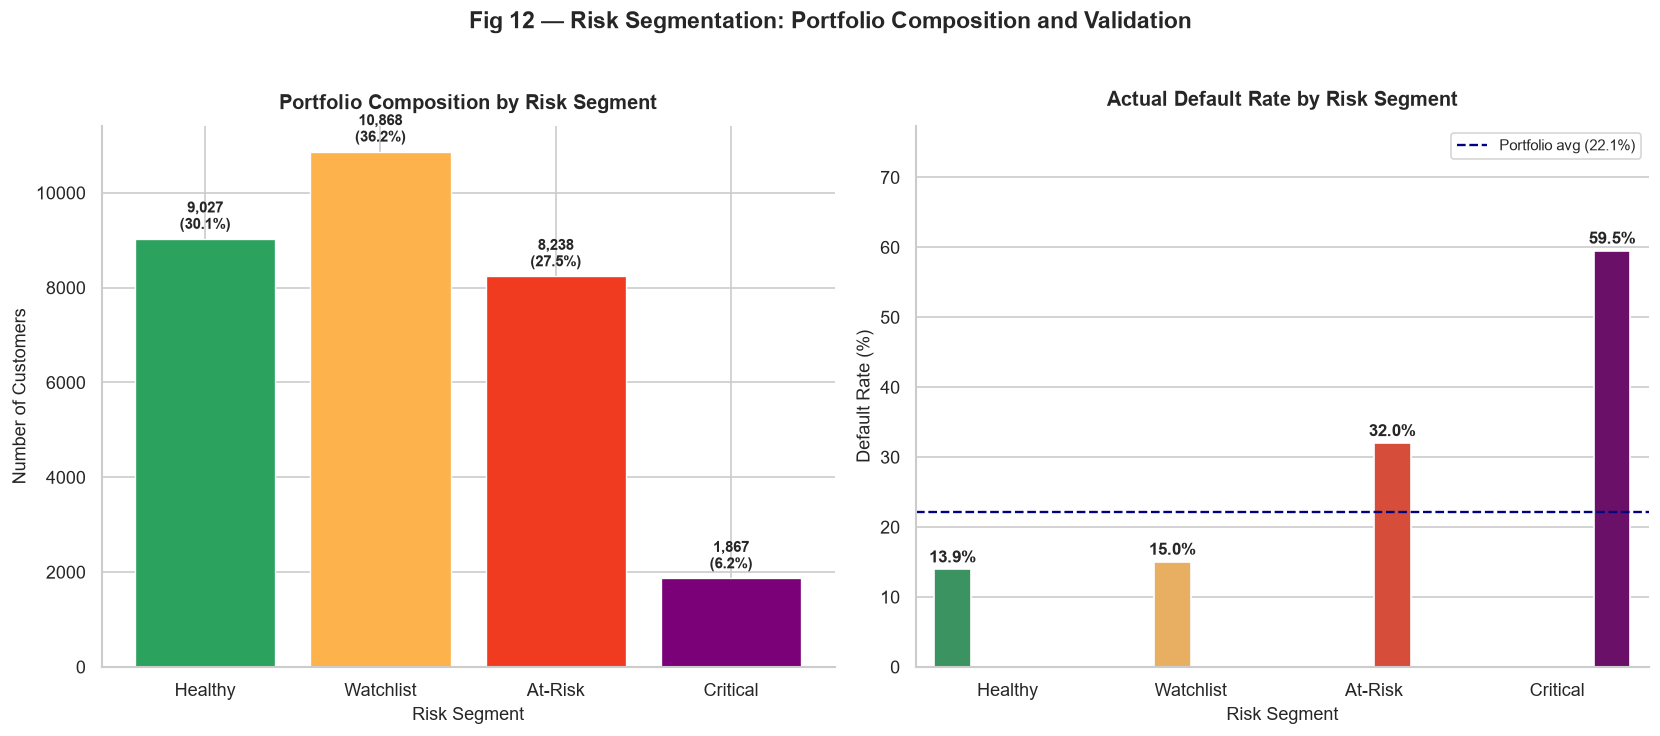

In [42]:
# ── Fig 12: Segment size + validation bar chart ──────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

seg_palette = [
    SEGMENT_COLOURS[s] for s in SEGMENT_ORDER
]

# Panel A — portfolio composition by segment
seg_counts = (
    df['risk_segment']
    .value_counts()
    .reindex(SEGMENT_ORDER)
)
bars = axes[0].bar(
    SEGMENT_ORDER, seg_counts.values,
    color=seg_palette, edgecolor='white', linewidth=0.8,
)
for bar, val, pct in zip(
    bars, seg_counts.values,
    validation['pct_of_portfolio'].values,
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        val + 120,
        f'{val:,}\n({pct:.1f}%)',
        ha='center', va='bottom', fontsize=9, fontweight='bold',
    )
axes[0].set_title(
    'Portfolio Composition by Risk Segment',
    fontsize=12, fontweight='bold', pad=10,
)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].set_xlabel('Risk Segment', fontsize=11)

# Panel B — actual default rate per segment (the validation)
plot_default_rate(
    df,
    group_col='risk_segment',
    title='Actual Default Rate by Risk Segment',
    xlabel='Risk Segment',
    ax=axes[1],
    order=SEGMENT_ORDER,
    palette=SEGMENT_COLOURS,
)

fig.suptitle(
    'Fig 12 — Risk Segmentation: '
    'Portfolio Composition and Validation',
    fontsize=14, fontweight='bold', y=1.02,
)
plt.tight_layout()
plt.savefig(
    'figures/fig12_segment_overview.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 12**  
The left panel shows that 66.3% of customers fall in the Healthy/Watchlist bands. Watchlist is the largest segment overall (36.2%), while At-Risk is the largest **elevated-risk action pool** at 27.5% and contains 39.7% of observed defaults. The right panel shows in-sample separation, from 13.9% in Healthy to 59.5% in Critical. This makes At-Risk a practical priority group, but the chart is descriptive validation on the same data used to define the heuristic scores.

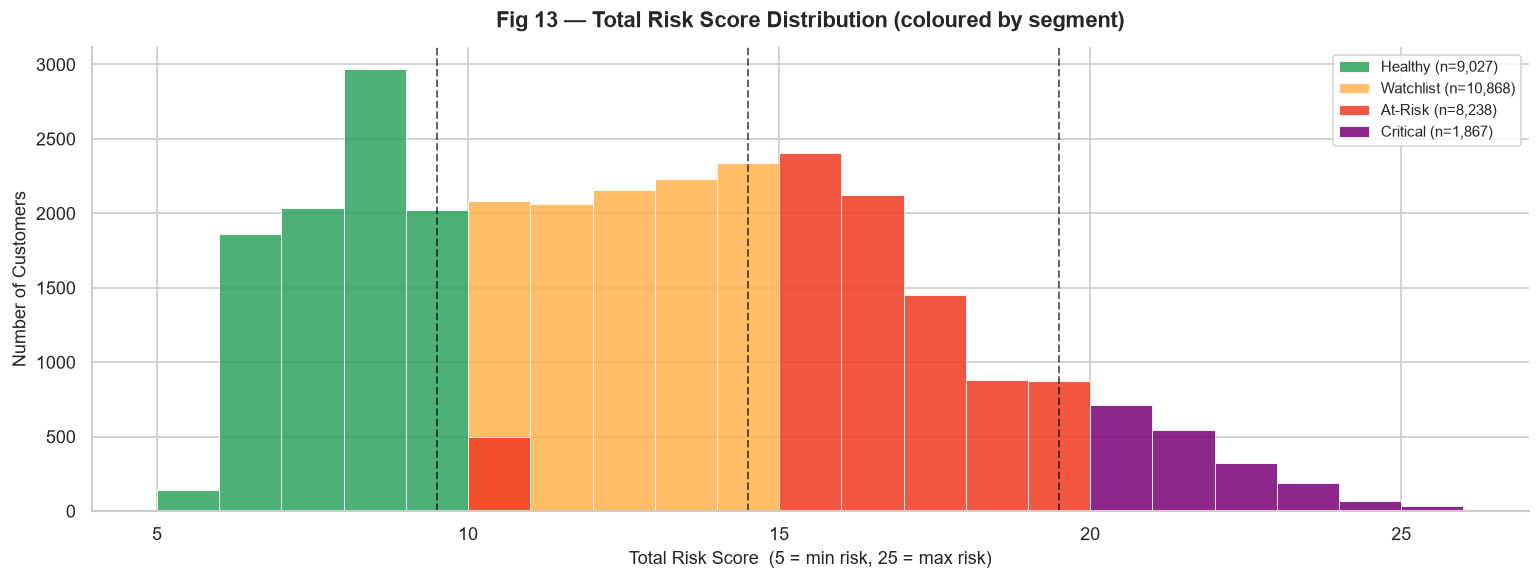

In [43]:
# ── Fig 13: Total risk score distribution ────────────────────────
# Histogram of all 30,000 scores, coloured by segment.
fig, ax = plt.subplots(figsize=(13, 5))

for seg, colour in SEGMENT_COLOURS.items():
    subset = df.loc[df['risk_segment'] == seg, 'total_risk_score']
    ax.hist(
        subset,
        bins=range(SCORE_MIN, SCORE_MAX + 2),
        color=colour,
        alpha=0.85,
        edgecolor='white',
        linewidth=0.6,
        label=f'{seg} (n={len(subset):,})',
    )

# Segment boundary lines
for boundary in SEGMENT_BINS[1:-1]:
    ax.axvline(
        boundary + 0.5, color='black',
        linestyle='--', linewidth=1.2, alpha=0.6,
    )

ax.set_title(
    'Fig 13 — Total Risk Score Distribution '
    '(coloured by segment)',
    fontsize=13, fontweight='bold', pad=12,
)
ax.set_xlabel(
    'Total Risk Score  '
    '(5 = min risk, 25 = max risk)',
    fontsize=11,
)
ax.set_ylabel('Number of Customers', fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(
    'figures/fig13_score_distribution.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 13**  
The score distribution is right-skewed: the large zero-delay population clusters at scores 5–9 (Healthy), while the long right tail represents the delinquent minority whose repeated delays and elevated secondary scores push them into At-Risk and Critical territory. The dashed segment-boundary lines confirm clean separation with no ambiguous overlap zones.

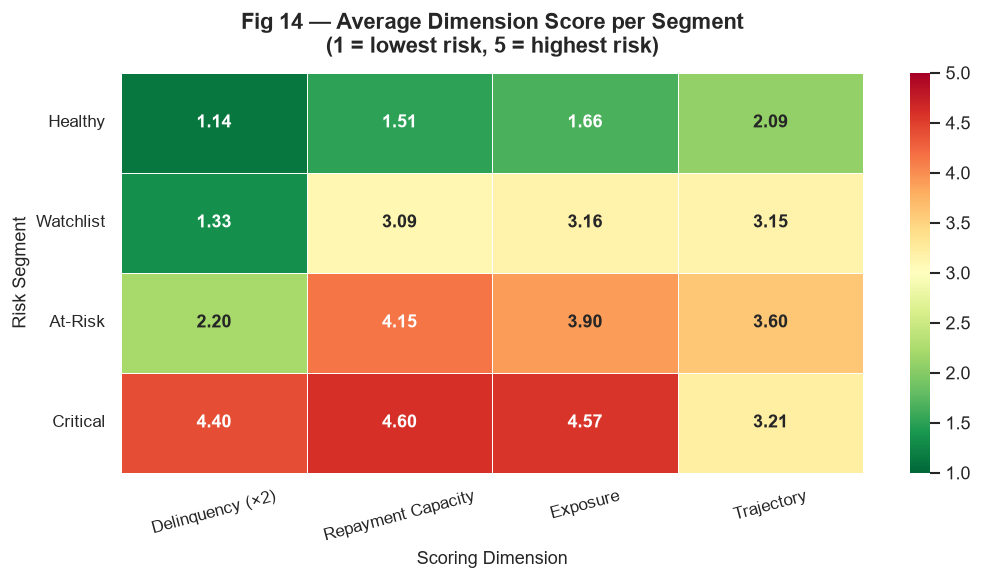

In [44]:
# ── Fig 14: Dimension score heatmap by segment ───────────────────
# Shows the average score on each of the four dimensions for
# each segment, revealing WHICH dimension drives each segment's
# elevated (or depressed) risk.
heatmap_data = validation[
    ['avg_delinquency', 'avg_repayment',
     'avg_exposure', 'avg_trajectory']
].rename(columns={
    'avg_delinquency': 'Delinquency (×2)',
    'avg_repayment':   'Repayment Capacity',
    'avg_exposure':    'Exposure',
    'avg_trajectory':  'Trajectory',
})

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn_r',
    vmin=1,
    vmax=5,
    linewidths=0.5,
    annot_kws={'size': 11, 'weight': 'bold'},
    ax=ax,
)
ax.set_title(
    'Fig 14 — Average Dimension Score per Segment\n'
    '(1 = lowest risk, 5 = highest risk)',
    fontsize=13, fontweight='bold', pad=12,
)
ax.set_xlabel('Scoring Dimension', fontsize=11)
ax.set_ylabel('Risk Segment', fontsize=11)
ax.tick_params(axis='x', rotation=15, labelsize=10)
ax.tick_params(axis='y', rotation=0, labelsize=10)
plt.tight_layout()
plt.savefig(
    'figures/fig14_dimension_heatmap.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 14**  
The heatmap reveals the *diagnostic story* behind each segment:

- **Healthy:** Low scores across all four dimensions — timely payers, decent repayment, low utilisation, flat balance.
- **Watchlist:** Delinquency is still near 1 (no delays yet) but repayment capacity, exposure, and trajectory are all elevated (~3.1). These customers are not yet late but are building the financial conditions that precede delinquency.
- **At-Risk:** Delinquency climbs to 2.2, meaning these customers have started missing payments — the transition point the bank must monitor most closely.
- **Critical:** Delinquency dominates at 4.4, with repayment capacity at 4.6. These customers have both a sustained history of delays AND near-zero repayment relative to their bills — the two strongest predictors of default in this portfolio.

### Cross-Validation Against Phase 2 Archetypes

The six defaulter archetypes from Phase 2 (Section 2.5) are recomputed here and compared against the Phase 3 segments to check that the scoring framework places each archetype into the segment that matches its known default behaviour.

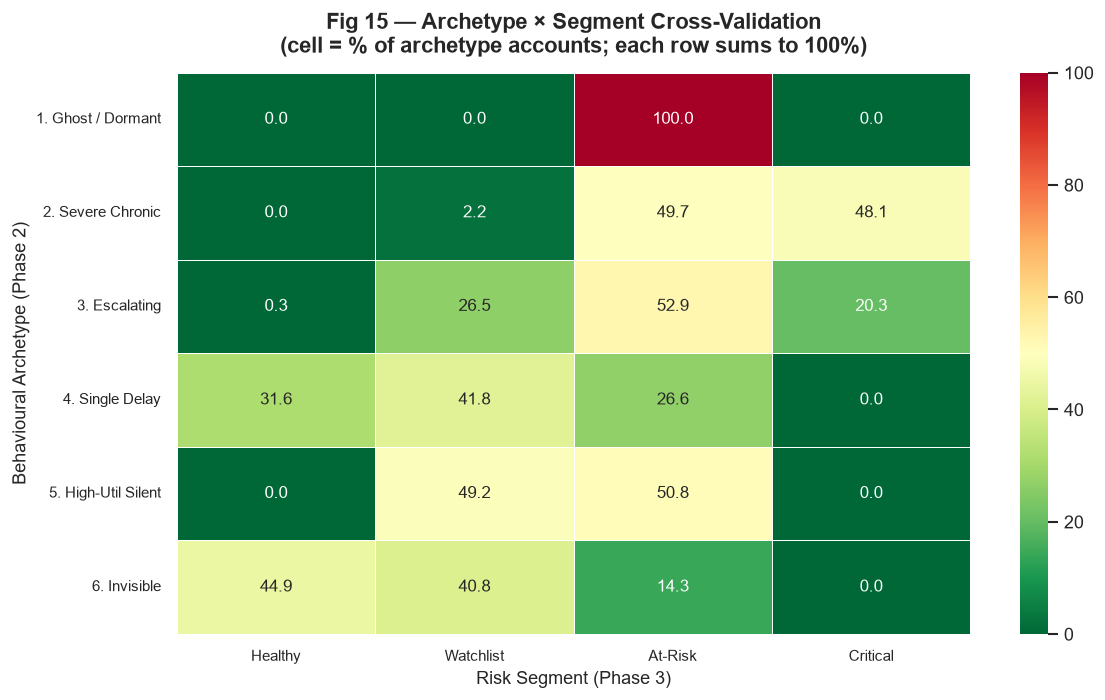

Archetype distribution across segments:
risk_segment         Healthy  Watchlist  At-Risk  Critical
archetype                                                 
1. Ghost / Dormant      0.00       0.00   100.00      0.00
2. Severe Chronic       0.00       2.20    49.70     48.10
3. Escalating           0.30      26.50    52.90     20.30
4. Single Delay        31.60      41.80    26.60      0.00
5. High-Util Silent     0.00      49.20    50.80      0.00
6. Invisible           44.90      40.80    14.30      0.00


In [45]:
# ── Recompute Phase 2 archetypes (standalone, no Phase 2 import)

# Threshold constants (mirrors Phase 2 Section 2.5)
GHOST_DELAY = 1
GHOST_INACTIVE = -2
SEVERE_DELAY = 4
ESCALATING_DELAY = 2
HIGH_UTIL = 0.80


def classify_archetype(row: pd.Series) -> str:
    """Assign one of six Phase 2 behavioural archetypes.

    Reproduced here for standalone cross-validation. Rules
    are evaluated in priority order (first match wins).

    Parameters
    ----------
    row : pd.Series
        Must contain 'is_ghost_account', 'num_delayed_months',
        and 'credit_utilization'.

    Returns
    -------
    str  One of six archetype labels.
    """
    if row['is_ghost_account']:
        return '1. Ghost / Dormant'
    if row['num_delayed_months'] >= SEVERE_DELAY:
        return '2. Severe Chronic'
    if row['num_delayed_months'] >= ESCALATING_DELAY:
        return '3. Escalating'
    if row['num_delayed_months'] == 1:
        return '4. Single Delay'
    if row['credit_utilization'] >= HIGH_UTIL:
        return '5. High-Util Silent'
    return '6. Invisible'


df['archetype'] = df.apply(classify_archetype, axis=1)

# ── Cross-tabulation (row = archetype, col = segment) ────────────
# Each row shows how that archetype's customers are distributed.
cross = (
    pd.crosstab(
        df['archetype'],
        df['risk_segment'],
        normalize='index',
    )
    .reindex(columns=SEGMENT_ORDER, fill_value=0)
    .mul(100)
)

assert np.allclose(cross.sum(axis=1), 100), (
    'Each archetype row must sum to 100%.'
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    cross.round(1),
    annot=True,
    fmt='.1f',
    cmap='RdYlGn_r',
    vmin=0, vmax=100,
    linewidths=0.4,
    annot_kws={'size': 10},
    ax=ax,
)
ax.set_title(
    'Fig 15 — Archetype × Segment Cross-Validation\n'
    '(cell = % of archetype accounts; each row sums to 100%)',
    fontsize=13, fontweight='bold', pad=12,
)
ax.set_xlabel('Risk Segment (Phase 3)', fontsize=11)
ax.set_ylabel('Behavioural Archetype (Phase 2)', fontsize=11)
ax.tick_params(axis='x', rotation=0, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)
plt.tight_layout()
plt.savefig(
    'figures/fig15_archetype_cross_validation.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

print('Archetype distribution across segments:')
print(cross.round(1).to_string())

**Interpretation — Fig 15**  
The customer-distribution cross-tabulation shows the expected structural alignment between the two heuristic frameworks:

- **Severe Chronic** places 97.8% of accounts in At-Risk/Critical, while **Escalating** places 73.2% there.
- **Ghost / Dormant** accounts are 100% At-Risk because of the documented override.
- The **Invisible** archetype is mostly Healthy/Watchlist (85.7%), showing the limitation of behaviour-only segmentation without implying that every account in this archetype defaults.
- **High-Util Silent** is split between Watchlist (49.2%) and At-Risk (50.8%), showing how utilisation raises the score even without repeated delays.

This is a consistency check between rule-based groupings, not independent predictive validation.

---
## Phase 3 Summary

| Step | Action | Outcome |
|-----:|:-------|:--------|
| 3.1a | Delinquency scored with fixed rules | Right-skewed distribution handled; scores 1–5 |
| 3.1b | Repayment capacity scored via qcut (reversed) | 1,071 undefined ratios → neutral 3; scores 1–5 |
| 3.1c | Exposure scored via qcut | Equal-frequency bins; scores 1–5 |
| 3.1d | Trajectory scored via qcut | Balance direction retained as a secondary input; scores 1–5 |
| 3.2 | Combined with Delinquency ×2 weighting | Total score range 5–25 |
| 3.2 | Ghost-account override | 495 dormant-fee accounts → At-Risk |
| 3.3 | In-sample monotonicity check | 13.9% → 15.0% → 32.0% → 59.5% ✓ |
| 3.4 | 4 visualisations produced | Figs 12–15 |
| 3.5 | Compared with Phase 2 archetypes | Rule-based consistency checked |

**Decision boundary:** this is an interpretable, historical segmentation framework checked against observed default rates on the same dataset, not a probability-of-default model, independent validation, or automatic decision engine. Use it to prioritise proportionate review and support; Phase 4 supplies the owner, cadence, and fair-treatment controls.  

**4 visualisations produced** (Figs 12–15), saved to `figures/`.  
**Proceed to Phase 4 — Strategic Recommendations.**

# Phase 4 - Strategic Recommendations

Translate validated segments into exposure priorities and proposed operating actions with owners, timing, review controls, and fair-treatment safeguards.

## Imports and Setup

In [46]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ── Display preferences ───────────────────────────────────────────
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
os.makedirs('figures', exist_ok=True)
print("Libraries loaded ✓")


Libraries loaded ✓


## Constants

In [47]:
# ── File path ────────────────────────────────────────────────────
CLEANED_PATH = "cleaned_credit_data.csv"

# ── Column groups ────────────────────────────────────────────────
PAY_STATUS_COLS = [f'pay_status_{i}' for i in range(1, 7)]
BILL_AMOUNT_COLS = [f'bill_amount_{i}' for i in range(1, 7)]
PAY_AMOUNT_COLS = [f'pay_amount_{i}' for i in range(1, 7)]
TARGET = 'default_next_month'

# ── Ghost-account detection (from Phase 2/3) ──────────────────────
GHOST_RECENT_STATUS = 1
GHOST_INACTIVE_CODE = -2

# ── Phase 3 scoring constants (reproduced for standalone use) ─────
DELINQUENCY_BINS = [-1, 0, 1, 2, 4, 6]
DELINQUENCY_LABELS = [1, 2, 3, 4, 5]
REPAYMENT_LABELS = [5, 4, 3, 2, 1]
REPAYMENT_NAN_SCORE = 3
EXPOSURE_LABELS = [1, 2, 3, 4, 5]
TRAJECTORY_LABELS = [1, 2, 3, 4, 5]
DELINQUENCY_WEIGHT = 2
SECONDARY_WEIGHT = 1
SEGMENT_BINS = [4, 9, 14, 19, 25]
SEGMENT_LABELS = ['Healthy', 'Watchlist', 'At-Risk', 'Critical']
SEGMENT_ORDER = ['Healthy', 'Watchlist', 'At-Risk', 'Critical']
SEGMENT_COLOURS = {
    'Healthy':   '#2ca25f',
    'Watchlist': '#feb24c',
    'At-Risk':   '#f03b20',
    'Critical':  '#7a0177',
}

# ── Phase 4 hypothesis-test thresholds ─────────────────────────────
# 50% utilisation is a common industry rule of thumb: revolving
# balances above half the credit limit are considered elevated
# risk by most card issuers.
HIGH_UTIL_THRESHOLD = 0.50
# Paying back less than a fifth of the average bill signals
# materially weak repayment capacity.
LOW_RATIO_THRESHOLD = 0.20

print("Constants defined ✓")


Constants defined ✓


---
## Load Data and Reproduce Phase 3 Segments

Full rationale for each scoring dimension is documented in the Phase 3 notebook; the pipeline is reproduced here compactly so this notebook can be tested independently. The stable Phase 1 CSV does not persist phase-specific reporting fields, so this notebook recreates the shared `credit_utilization = avg_bill_amount / credit_limit`, clipped at zero. `age_group` and `credit_limit_tier` are Phase 2 EDA fields and are not required for Phase 4 strategy.

In [48]:
df = pd.read_csv(CLEANED_PATH)

assert df.shape == (30_000, 34), (
    f'Unexpected shape {df.shape}; expected (30000, 34).'
)

# ── Derived columns (shared Phase 2-4 definitions) ─────────────────
df['credit_utilization'] = (
    df['avg_bill_amount'] / df['credit_limit']
).clip(lower=0)

# Outstanding balance exposure: negative bills (credit-balance
# customers) are clipped to 0 since they represent money owed TO
# the customer, not exposure the bank is carrying.
df['outstanding_exposure'] = df['avg_bill_amount'].clip(lower=0)

df['is_ghost_account'] = (
    (df['pay_status_1'] == GHOST_RECENT_STATUS)
    & df[BILL_AMOUNT_COLS].eq(0).all(axis=1)
    & df[PAY_AMOUNT_COLS].eq(0).all(axis=1)
    & df[
        ['pay_status_2', 'pay_status_3', 'pay_status_4',
         'pay_status_5', 'pay_status_6']
    ].eq(GHOST_INACTIVE_CODE).all(axis=1)
)

# ── Phase 3 dimension scores ────────────────────────────────────────
delinquency_score = pd.cut(
    df['num_delayed_months'], bins=DELINQUENCY_BINS,
    labels=DELINQUENCY_LABELS, right=True,
).astype(int)

repayment_score = pd.qcut(
    df['pay_to_bill_ratio'], q=5,
    labels=REPAYMENT_LABELS, duplicates='drop',
).astype(float).fillna(REPAYMENT_NAN_SCORE).astype(int)

exposure_score = pd.qcut(
    df['credit_utilization'], q=5,
    labels=EXPOSURE_LABELS, duplicates='drop',
).astype(int)

trajectory_score = pd.qcut(
    df['balance_trend'], q=5,
    labels=TRAJECTORY_LABELS, duplicates='drop',
).astype(int)

df['total_risk_score'] = (
    DELINQUENCY_WEIGHT * delinquency_score
    + SECONDARY_WEIGHT * repayment_score
    + SECONDARY_WEIGHT * exposure_score
    + SECONDARY_WEIGHT * trajectory_score
)

df['risk_segment'] = pd.cut(
    df['total_risk_score'], bins=SEGMENT_BINS,
    labels=SEGMENT_LABELS, right=True, include_lowest=True,
).astype(str)

# Ghost-account override (see Phase 3 for full justification)
df.loc[df['is_ghost_account'], 'risk_segment'] = 'At-Risk'

OVERALL_DR = df[TARGET].mean() * 100

print(f"Segments reproduced ✓")
print(df['risk_segment'].value_counts().reindex(SEGMENT_ORDER))


Segments reproduced ✓


risk_segment
Healthy       9027
Watchlist    10868
At-Risk       8238
Critical      1867
Name: count, dtype: int64


---
## Section 4.1 — Credit Utilisation and Exposure Investigation

Before testing the interaction hypothesis, we first look at how utilisation, outstanding balance, and credit limit each vary independently across the four risk segments.

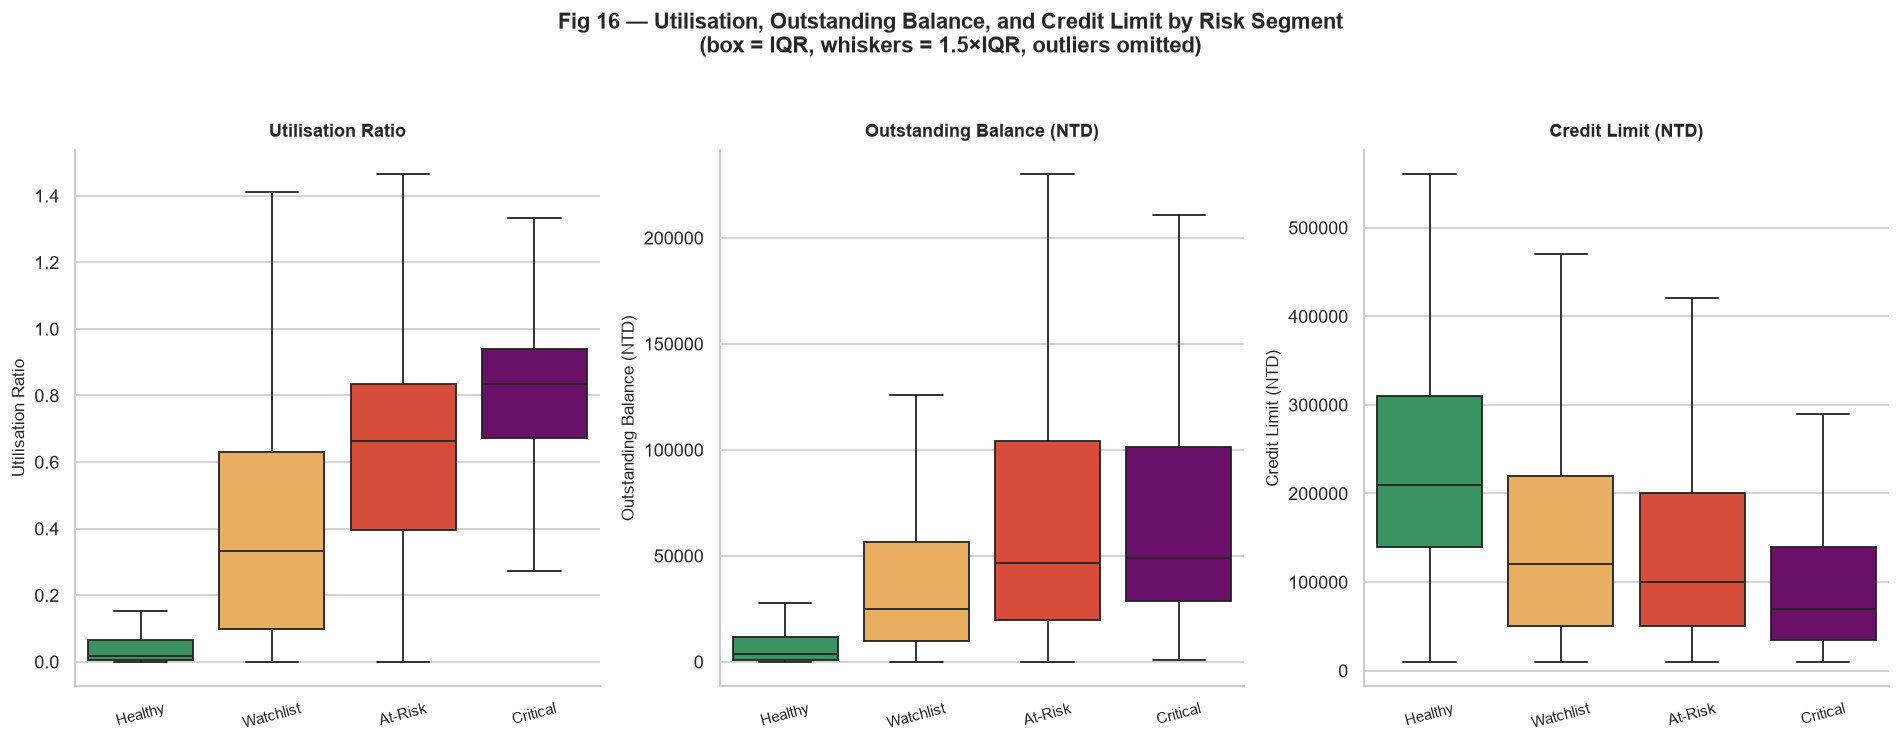

Median values by segment:
              credit_utilization  outstanding_exposure  credit_limit
risk_segment                                                        
Healthy                     0.02              3,494.17    210,000.00
Watchlist                   0.33             24,881.75    120,000.00
At-Risk                     0.66             46,582.08    100,000.00
Critical                    0.84             48,852.83     70,000.00


In [49]:
# ── Fig 16: Utilisation, balance, and limit by segment ───────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

panels = [
    ('credit_utilization', 'Utilisation Ratio', axes[0]),
    ('outstanding_exposure', 'Outstanding Balance (NTD)', axes[1]),
    ('credit_limit', 'Credit Limit (NTD)', axes[2]),
]

for col, label, ax in panels:
    sns.boxplot(
        data=df, x='risk_segment', y=col,
        hue='risk_segment', order=SEGMENT_ORDER,
        hue_order=SEGMENT_ORDER,
        palette=SEGMENT_COLOURS, legend=False,
        showfliers=False, linewidth=1.1, ax=ax,
    )
    ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel('')
    ax.set_ylabel(label, fontsize=10)
    ax.tick_params(axis='x', labelsize=9, rotation=15)

fig.suptitle(
    'Fig 16 — Utilisation, Outstanding Balance, and Credit '
    'Limit by Risk Segment\n'
    '(box = IQR, whiskers = 1.5×IQR, outliers omitted)',
    fontsize=13, fontweight='bold', y=1.03,
)
plt.tight_layout()
plt.savefig(
    'figures/fig16_utilization_balance_limit.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

print('Median values by segment:')
print(
    df.groupby('risk_segment', observed=True)[
        ['credit_utilization', 'outstanding_exposure', 'credit_limit']
    ].median().reindex(SEGMENT_ORDER).round(2).to_string()
)


**Interpretation — Fig 16**  
Utilisation rises steadily from Healthy through Critical, confirming the scoring framework's exposure dimension is behaving as intended. Outstanding balance follows the same upward pattern. Credit limit, however, moves in the **opposite direction** — Critical customers hold noticeably smaller limits than Healthy customers. Together this means Critical customers are maxing out a *smaller* line of credit, while Healthy customers carry a *larger* limit they barely touch. Limit size alone is not the driver of risk — **how much of it is used, relative to what's granted, is what matters.**

---
## Section 4.2 — Testing the Utilisation × Repayment Hypothesis

The business mandate asks specifically whether customers combining **high utilisation** with **weak repayment behaviour** contribute disproportionately to default risk. Two reusable classifier functions split the portfolio into four quadrants to test this directly.

Unlike the Phase 3 `qcut` scores, these are fixed business thresholds: high utilisation is `>= 50%` of the credit limit and poor repayment is `< 20%` of the average bill. Fixed cut-offs make the quadrant labels stable and operationally interpretable across reruns. The 1,071 customers with undefined `pay_to_bill_ratio` are excluded from this two-variable quadrant only; they remain in all segment and exposure totals, and no repayment band is invented for them.

In [50]:
def classify_utilization_band(credit_utilization: pd.Series) -> pd.Series:
    """Classify customers into high/low utilisation bands.

    Uses a fixed 50% threshold rather than a quantile split so
    the bands carry a fixed, business-interpretable meaning
    (independent of how this particular portfolio happens to be
    distributed).

    Parameters
    ----------
    credit_utilization : pd.Series
        avg_bill_amount / credit_limit, clipped at 0.

    Returns
    -------
    pd.Series of str
        'High Utilization (≥50%)' or 'Low Utilization (<50%)'.
    """
    return pd.Series(
        np.where(
            credit_utilization >= HIGH_UTIL_THRESHOLD,
            'High Utilization (≥50%)',
            'Low Utilization (<50%)',
        ),
        index=credit_utilization.index,
    )


def classify_repayment_band(
    pay_to_bill_ratio: pd.Series,
) -> pd.Series:
    """Classify customers into adequate/poor repayment bands.

    NaN ratios (credit-balance customers with zero or negative
    average bills) are explicitly preserved as NaN rather than
    silently defaulting to 'Adequate' — this dimension has no
    meaning for them and they must be excluded downstream.

    Parameters
    ----------
    pay_to_bill_ratio : pd.Series
        Ratio of avg payment to avg bill. May contain NaN.

    Returns
    -------
    pd.Series of str (with NaN preserved)
        'Poor Repayment (<20%)' or 'Adequate Repayment (≥20%)'.
    """
    band = pd.Series(
        np.where(
            pay_to_bill_ratio < LOW_RATIO_THRESHOLD,
            'Poor Repayment (<20%)',
            'Adequate Repayment (≥20%)',
        ),
        index=pay_to_bill_ratio.index,
    )
    return band.where(pay_to_bill_ratio.notna())


df['util_band'] = classify_utilization_band(df['credit_utilization'])
df['ratio_band'] = classify_repayment_band(
    df['pay_to_bill_ratio']
)

# ── Exclude undefined-ratio customers from this analysis ────────
# These 1,071 zero/negative-average-bill accounts are distinct
# from the separate any-negative-month flag; the ratio is undefined.
excluded_n = df['ratio_band'].isna().sum()
quadrant_df = df.dropna(subset=['ratio_band']).copy()

print(f"Excluded (undefined repayment ratio): {excluded_n:,} rows")
print(f"Analysed: {len(quadrant_df):,} rows")


Excluded (undefined repayment ratio): 1,071 rows
Analysed: 28,929 rows


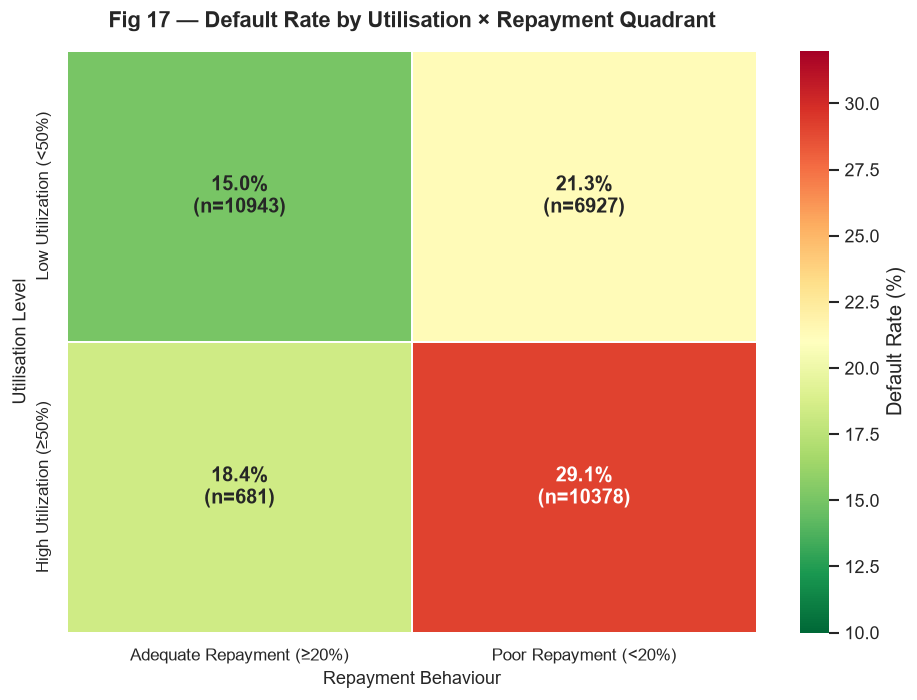

High-Utilisation + Poor-Repayment customers: 10,378 (34.6% of portfolio)
They account for 3,021 defaults (45.5% of ALL defaults in the dataset)


In [51]:
# ── Build the 2x2 quadrant matrix ────────────────────────────────
UTIL_ORDER = ['Low Utilization (<50%)', 'High Utilization (≥50%)']
RATIO_ORDER = [
    'Adequate Repayment (≥20%)', 'Poor Repayment (<20%)'
]

pivot_default_rate = (
    quadrant_df.pivot_table(
        values=TARGET, index='util_band',
        columns='ratio_band', aggfunc='mean',
    )
    .reindex(index=UTIL_ORDER, columns=RATIO_ORDER)
    * 100
)
pivot_count = (
    quadrant_df.pivot_table(
        values='customer_id', index='util_band',
        columns='ratio_band', aggfunc='count',
    )
    .reindex(index=UTIL_ORDER, columns=RATIO_ORDER)
)

# Combined annotation: default rate % on top, n below
annot_labels = (
    pivot_default_rate.round(1).astype(str) + '%\n(n='
    + pivot_count.astype(str) + ')'
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    pivot_default_rate,
    annot=annot_labels,
    fmt='',
    cmap='RdYlGn_r',
    vmin=10, vmax=32,
    linewidths=1.0,
    linecolor='white',
    annot_kws={'size': 12, 'weight': 'bold'},
    cbar_kws={'label': 'Default Rate (%)'},
    ax=ax,
)
ax.set_title(
    'Fig 17 — Default Rate by Utilisation × Repayment '
    'Quadrant',
    fontsize=13, fontweight='bold', pad=14,
)
ax.set_xlabel('Repayment Behaviour', fontsize=11)
ax.set_ylabel('Utilisation Level', fontsize=11)
ax.tick_params(axis='x', labelsize=10, rotation=0)
ax.tick_params(axis='y', labelsize=10, rotation=90)
plt.tight_layout()
plt.savefig(
    'figures/fig17_utilization_repayment_quadrant.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

# ── Quantify the disproportionate-contribution claim ─────────────
high_risk_quadrant = quadrant_df[
    (quadrant_df['util_band'] == UTIL_ORDER[1])
    & (quadrant_df['ratio_band'] == RATIO_ORDER[1])
]
total_defaulters = df[TARGET].sum()
quadrant_defaulters = high_risk_quadrant[TARGET].sum()

print(
    f'High-Utilisation + Poor-Repayment customers: '
    f'{len(high_risk_quadrant):,} '
    f'({len(high_risk_quadrant) / len(df) * 100:.1f}% '
    f'of portfolio)'
)
print(
    f'They account for {quadrant_defaulters:,} defaults '
    f'({quadrant_defaulters / total_defaulters * 100:.1f}% '
    f'of ALL defaults in the dataset)'
)


**Interpretation — Fig 17**  
The bottom-right quadrant confirms the hypothesis: customers with **both** high utilisation and poor repayment default at **29.1%** — the highest of any combination, and roughly double the safest quadrant (15.0%). More importantly, this group is not a small fringe case: at **10,378 customers (34.6% of the entire portfolio)**, they account for **45.5% of every default in the dataset** — a disproportionate concentration of risk relative to their share of the customer base. Notably, high utilisation *alone* (adequate repayment) is comparatively mild (18.4%, only 681 customers) — it is the **combination**, not either factor in isolation, that identifies the highest-value target for intervention.

---
## Section 4.3 — Financial Exposure and Expected Loss by Segment

Addresses the mandate's third question directly: *"where is the company over-exposed... and what is the financial significance of these accounts?"*

**Expected loss** is estimated here as:

```
expected_loss = total_outstanding_balance x observed_default_rate
```

**Stated assumption:** this simplified estimate assumes 100% loss given default (no recovery through collections). A production credit-risk model would apply a recovery-rate haircut; that refinement is out of scope here, but the relative comparison *between segments* remains valid and directionally sound.

In [52]:
# ── Segment-level financial exposure ──────────────────────────────
exposure_summary = (
    df.groupby('risk_segment', observed=True)
    .agg(
        n=('customer_id', 'count'),
        total_credit_limit=('credit_limit', 'sum'),
        total_outstanding=('outstanding_exposure', 'sum'),
        default_rate=(TARGET, 'mean'),
    )
    .reindex(SEGMENT_ORDER)
)

exposure_summary['expected_loss'] = (
    exposure_summary['total_outstanding']
    * exposure_summary['default_rate']
)
exposure_summary['pct_of_expected_loss'] = (
    exposure_summary['expected_loss']
    / exposure_summary['expected_loss'].sum() * 100
)

# ── Reconciliation check ─────────────────────────────────────────
assert exposure_summary['n'].sum() == len(df), (
    'Segment counts must reconcile to 30,000.'
)

display_summary = exposure_summary.copy()
for col in ['total_credit_limit', 'total_outstanding',
            'expected_loss']:
    display_summary[f'{col}_millions'] = (
        display_summary[col] / 1_000_000
    ).round(1)

print('Financial exposure by segment (NTD millions):')
display_summary[[
    'n', 'total_credit_limit_millions',
    'total_outstanding_millions', 'expected_loss_millions',
    'pct_of_expected_loss',
]].round(1)


Financial exposure by segment (NTD millions):


,n,total_credit_limit_millions,total_outstanding_millions,expected_loss_millions,pct_of_expected_loss
risk_segment,,,,,
Healthy,9027,"2,048.20",108.40,15.10,4.10
Watchlist,10868,"1,669.60",477.40,71.70,19.30
At-Risk,8238,"1,119.50",619.70,198.20,53.40
Critical,1867,187.30,144.20,85.80,23.10


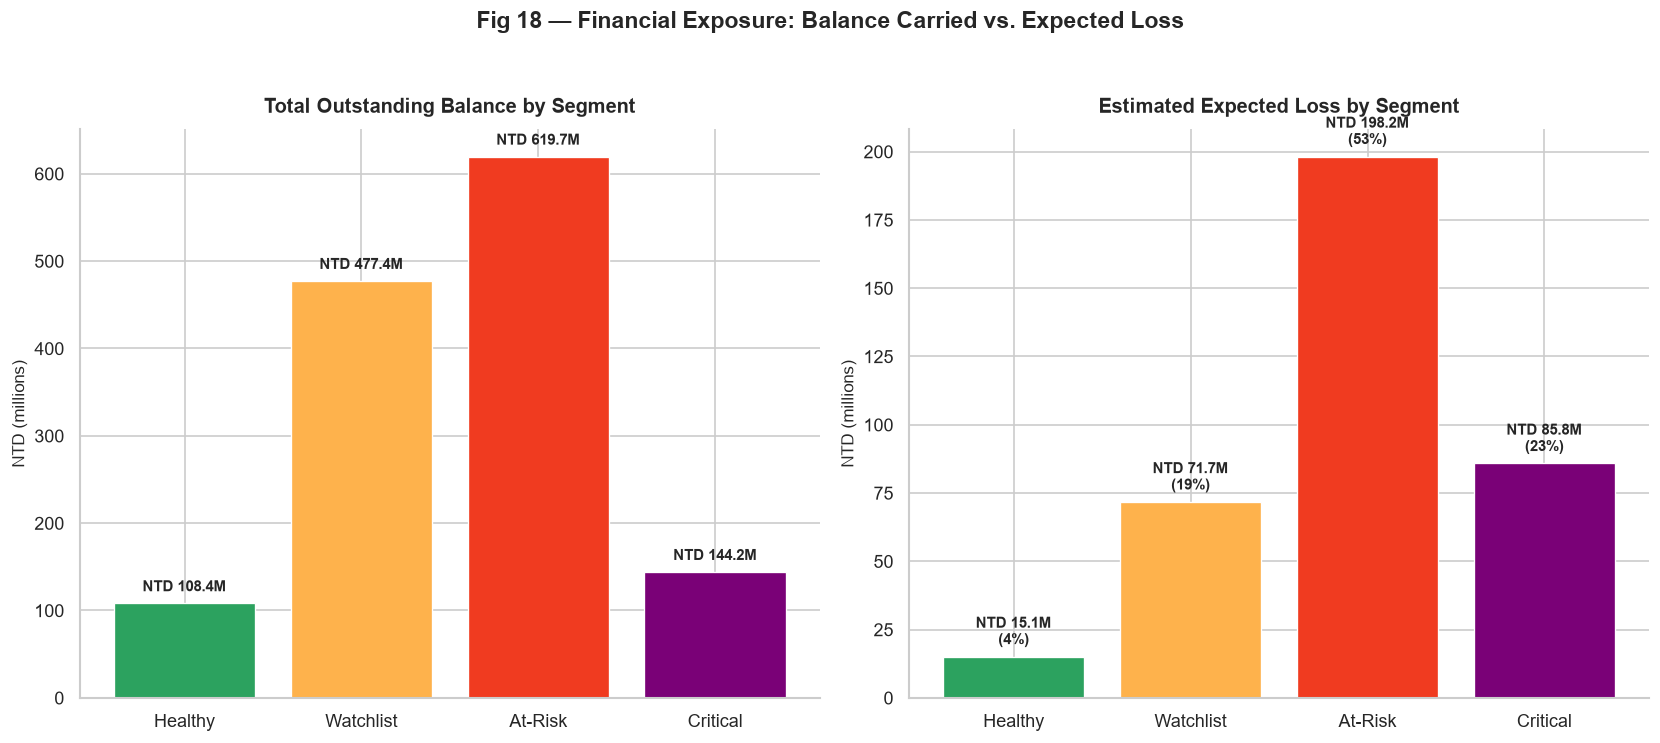

In [53]:
# ── Fig 18: Total outstanding vs expected loss by segment ────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
seg_palette = [SEGMENT_COLOURS[s] for s in SEGMENT_ORDER]

# Panel A — total outstanding balance per segment
bars_a = axes[0].bar(
    SEGMENT_ORDER,
    display_summary['total_outstanding_millions'],
    color=seg_palette, edgecolor='white', linewidth=0.8,
)
for bar, val in zip(
    bars_a, display_summary['total_outstanding_millions']
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, val + 10,
        f'NTD {val:,.1f}M', ha='center', va='bottom',
        fontsize=9, fontweight='bold',
    )
axes[0].set_title(
    'Total Outstanding Balance by Segment',
    fontsize=12, fontweight='bold', pad=10,
)
axes[0].set_ylabel('NTD (millions)', fontsize=10)

# Panel B — estimated expected loss per segment
bars_b = axes[1].bar(
    SEGMENT_ORDER,
    display_summary['expected_loss_millions'],
    color=seg_palette, edgecolor='white', linewidth=0.8,
)
for bar, val, pct in zip(
    bars_b, display_summary['expected_loss_millions'],
    display_summary['pct_of_expected_loss'],
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, val + 3,
        f'NTD {val:,.1f}M\n({pct:.0f}%)',
        ha='center', va='bottom', fontsize=9, fontweight='bold',
    )
axes[1].set_title(
    'Estimated Expected Loss by Segment',
    fontsize=12, fontweight='bold', pad=10,
)
axes[1].set_ylabel('NTD (millions)', fontsize=10)

fig.suptitle(
    'Fig 18 — Financial Exposure: Balance Carried vs. '
    'Expected Loss',
    fontsize=14, fontweight='bold', y=1.03,
)
plt.tight_layout()
plt.savefig(
    'figures/fig18_financial_exposure.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 18 (the key non-obvious finding of this phase)**  
The **Critical** segment has the highest default *rate* (60%), but it is the **At-Risk** segment that carries the largest **expected loss in absolute NTD** — approximately NTD 198.2M, or **53% of the portfolio's entire expected loss**, compared to just 23% from Critical. This happens because At-Risk is more than four times larger than Critical (8,238 vs 1,867 customers) and carries substantially higher outstanding balances per customer.  

**This is the single most important strategic implication of Phase 4:** if FinTrust has limited collections capacity, prioritising outreach purely by default *rate* (i.e. chasing Critical accounts first) would leave the largest pool of actual money at risk unaddressed. **At-Risk deserves equal or greater resourcing priority**, not because its customers are individually riskiest, but because of the segment's sheer size and financial scale.

---
## Section 4.4 — Strategic Action Mapping

Each segment is mapped to a specific, proportionate action via a dictionary. **Ghost/dormant accounts** (identified in Phase 2/3) receive a distinct override: they are technically labelled At-Risk by score, but a credit review or restructuring offer makes no sense for a dormant, zero-balance account. Their action addresses the actual root cause — disengagement, not financial distress.

In [54]:
# ── Action dictionary: one clear, proportionate action per segment
ACTION_MAP = {
    'Healthy': (
        'Maintain standard servicing. Offer optional loyalty or '
        'rewards incentives to reinforce good repayment habits. '
        'No active risk intervention required.'
    ),
    'Watchlist': (
        'Send automated payment reminders 3-5 days before the due '
        'date. Share financial-wellness resources proactively. '
        'Increase monitoring cadence to monthly.'
    ),
    'At-Risk': (
        'Conduct a credit-limit review (freeze further increases '
        'or reduce limit). Proactively offer a structured '
        'repayment plan. Assign to enhanced monitoring.'
    ),
    'Critical': (
        'Escalate to dedicated case management. Offer '
        'hardship-based restructuring or a settlement plan. '
        'Suspend further credit extension pending review.'
    ),
}

GHOST_ACTION = (
    'Send a dormant-account re-engagement notice (fee-due alert '
    'or account status reminder) before any credit action. '
    'Standard restructuring or limit-review offers are not '
    'appropriate for a zero-balance, inactive account.'
)


def assign_recommended_action(row: pd.Series) -> str:
    """Return the recommended action for a single customer.

    Ghost/dormant accounts are checked first and receive a
    re-engagement action regardless of their scored segment,
    since standard segment actions assume active financial
    behaviour that dormant accounts do not exhibit.

    Parameters
    ----------
    row : pd.Series
        Must contain 'is_ghost_account' and 'risk_segment'.

    Returns
    -------
    str
        The recommended business action.
    """
    if row['is_ghost_account']:
        return GHOST_ACTION
    return ACTION_MAP[row['risk_segment']]


df['recommended_action'] = df.apply(
    assign_recommended_action, axis=1
)

assert df['recommended_action'].notna().all(), (
    'Every customer must receive a recommended action.'
)

# ── Display segment breakdown, separating ghost accounts out ─────
df['segment_display'] = np.where(
    df['is_ghost_account'],
    'At-Risk — Ghost/Dormant',
    df['risk_segment'],
)
DISPLAY_ORDER = [
    'Healthy', 'Watchlist', 'At-Risk',
    'At-Risk — Ghost/Dormant', 'Critical',
]

action_summary = (
    df.groupby('segment_display', observed=True)
    .agg(
        n=('customer_id', 'count'),
        default_rate=(TARGET, 'mean'),
        total_outstanding=('outstanding_exposure', 'sum'),
    )
    .reindex(DISPLAY_ORDER)
)
action_summary['default_rate_pct'] = (
    action_summary['default_rate'] * 100
).round(1)
action_summary['total_outstanding_millions'] = (
    action_summary['total_outstanding'] / 1_000_000
).round(1)

action_summary[[
    'n', 'default_rate_pct', 'total_outstanding_millions'
]]


,n,default_rate_pct,total_outstanding_millions
segment_display,,,
Healthy,9027,13.90,108.40
Watchlist,10868,15.00,477.40
At-Risk,7743,31.50,619.70
At-Risk — Ghost/Dormant,495,39.60,0.00
Critical,1867,59.50,144.20


**Segment → Action Reference Table**

| Segment | n | Default Rate | Recommended Action |
|:--------|--:|-------------:|:--------------------|
| 🟢 Healthy | 9,027 | 13.9% | Standard servicing; optional loyalty rewards |
| 🟡 Watchlist | 10,868 | 15.0% | Automated reminders; financial-wellness content; monthly monitoring |
| 🟠 At-Risk | 7,743 | 31.5%* | Credit-limit review; structured repayment plan; enhanced monitoring |
| 🟣 At-Risk — Ghost/Dormant | 495 | 39.6% | Dormant-account re-engagement notice, **not** restructuring |
| 🔴 Critical | 1,867 | 59.5% | Case management; hardship restructuring; suspend further credit |

*At-Risk default rate shown excluding the Ghost/Dormant sub-population, which is broken out separately above because it requires a fundamentally different action.

**Fairness and transparency note:** every action is grounded in observable repayment behaviour (delinquency, repayment ratio, utilisation, trajectory) — never demographic attributes such as age, sex, education, or marital status. This satisfies the mandate's requirement that interventions remain "fair and transparent."

**A note on the Invisible Defaulters (Phase 2 finding):** the 1,951 customers who defaulted with zero behavioural warning signs are, by construction, indistinguishable from genuinely healthy customers and will be assigned the Healthy or Watchlist action. No behavioural score can target them individually — the appropriate response is portfolio-level (e.g. a standing reserve for unpredictable losses, or the external-data enrichment explored in Phase 5), not a segment-specific action.

---
## Section 4.4b - Proposed Operating Playbook

The actions above are converted below into a practical operating proposal. Owners, timing, and triggers are **recommended controls**, not historical FinTrust policy. Segment assignments should be refreshed monthly from the same behaviour-led logic; any intervention that could reduce credit access requires an individual review rather than automatic execution.

In [55]:
# Proposed operating controls; these do not change the segmentation or score.
OPERATING_PLAYBOOK = pd.DataFrame(
    [
        {
            'segment': 'Healthy',
            'action': 'Maintain standard servicing; offer optional loyalty support.',
            'owner': 'Customer Engagement / CRM',
            'trigger': 'Healthy result at monthly segment refresh.',
            'timing': 'Ongoing service; review only after the next monthly refresh.',
            'fair_treatment': 'No adverse action; apply any loyalty eligibility consistently.',
        },
        {
            'segment': 'Watchlist',
            'action': 'Send payment reminder and financial-wellness support.',
            'owner': 'Customer Engagement / CRM',
            'trigger': 'Watchlist result at monthly segment refresh.',
            'timing': 'Send reminder 3-5 days before due date; reassess monthly.',
            'fair_treatment': 'Supportive outreach only; do not automatically reduce a limit.',
        },
        {
            'segment': 'At-Risk',
            'action': 'Review limit and offer a structured repayment plan.',
            'owner': 'Credit Risk and Collections',
            'trigger': 'At-Risk result at monthly segment refresh.',
            'timing': 'Contact within 5 business days; monitor monthly.',
            'fair_treatment': 'Require individual review before credit changes; use behaviour and hardship evidence, not demographics.',
        },
        {
            'segment': 'At-Risk - Ghost/Dormant',
            'action': 'Send re-engagement or account-status notice before credit action.',
            'owner': 'Account Servicing / Customer Engagement',
            'trigger': 'is_ghost_account is true.',
            'timing': 'Send notice within 5 business days; reassess at response or next refresh.',
            'fair_treatment': 'Do not escalate collections or reduce limits without active exposure or delinquency evidence.',
        },
        {
            'segment': 'Critical',
            'action': 'Assign case management; assess hardship or settlement options.',
            'owner': 'Collections and Hardship Support',
            'trigger': 'Critical result at monthly segment refresh.',
            'timing': 'Assign a case within 1 business day; review the case weekly.',
            'fair_treatment': 'Assess affordability individually and provide a clear explanation and contact route before adverse action.',
        },
    ]
)

assert OPERATING_PLAYBOOK['segment'].is_unique
assert set(OPERATING_PLAYBOOK['segment']) == {
    'Healthy', 'Watchlist', 'At-Risk', 'At-Risk - Ghost/Dormant', 'Critical'
}

OPERATING_PLAYBOOK.set_index('segment')


,action,owner,trigger,timing,fair_treatment
segment,,,,,
Healthy,Maintain standard servicing; offer optional lo...,Customer Engagement / CRM,Healthy result at monthly segment refresh.,Ongoing service; review only after the next mo...,No adverse action; apply any loyalty eligibili...
Watchlist,Send payment reminder and financial-wellness s...,Customer Engagement / CRM,Watchlist result at monthly segment refresh.,Send reminder 3-5 days before due date; reasse...,Supportive outreach only; do not automatically...
At-Risk,Review limit and offer a structured repayment ...,Credit Risk and Collections,At-Risk result at monthly segment refresh.,Contact within 5 business days; monitor monthly.,Require individual review before credit change...
At-Risk - Ghost/Dormant,Send re-engagement or account-status notice be...,Account Servicing / Customer Engagement,is_ghost_account is true.,Send notice within 5 business days; reassess a...,Do not escalate collections or reduce limits w...
Critical,Assign case management; assess hardship or set...,Collections and Hardship Support,Critical result at monthly segment refresh.,Assign a case within 1 business day; review th...,Assess affordability individually and provide ...


**Control principle:** operational owners should retain the segment result, the behavioural reasons that support it, and the outcome of any manual review. This makes the process auditable, enables challenge or correction, and keeps demographic attributes out of automated adverse-action decisions.

---
## Section 4.5 - Consolidated Risk-Segment Summary

This report-ready table brings the validated segmentation, behavioural measures, financial exposure, expected loss, and normal segment action into one reference. It uses the four mutually exclusive risk segments so all counts and expected-loss totals reconcile to the 30,000-customer portfolio. The 495 ghost/dormant accounts remain within At-Risk for portfolio totals, but use the separate re-engagement action shown in Section 4.4.

Median pay-to-bill ratio is used instead of the mean because a small number of extreme ratios would otherwise distort the typical repayment view.

In [56]:
# ── Consolidated segment reference for report and viva use ─────────
SUMMARY_ACTION_MAP = {
    'Healthy': 'Standard servicing; optional loyalty',
    'Watchlist': 'Pre-due reminders; monthly monitoring',
    'At-Risk': 'Limit review; repayment plan; enhanced monitoring',
    'Critical': 'Case management; hardship review; suspend credit',
}

final_segment_summary = (
    df.groupby('risk_segment', observed=True)
    .agg(
        n=('customer_id', 'count'),
        avg_total_risk_score=('total_risk_score', 'mean'),
        avg_delayed_months=('num_delayed_months', 'mean'),
        median_pay_to_bill_ratio=('pay_to_bill_ratio', 'median'),
        avg_credit_utilization=('credit_utilization', 'mean'),
    )
    .reindex(SEGMENT_ORDER)
)

final_segment_summary['portfolio_share_pct'] = (
    final_segment_summary['n'] / len(df) * 100
)
final_segment_summary['default_rate_pct'] = (
    exposure_summary['default_rate'] * 100
)
final_segment_summary['total_outstanding_millions'] = (
    exposure_summary['total_outstanding'] / 1_000_000
)
final_segment_summary['expected_loss_millions'] = (
    exposure_summary['expected_loss'] / 1_000_000
)
final_segment_summary['pct_of_expected_loss'] = (
    exposure_summary['pct_of_expected_loss']
)
final_segment_summary['recommended_action'] = (
    pd.Series(SUMMARY_ACTION_MAP).reindex(SEGMENT_ORDER)
)

assert final_segment_summary['n'].sum() == len(df), (
    'Final segment table must reconcile to 30,000 customers.'
)
assert round(final_segment_summary['expected_loss_millions'].sum(), 1) == round(
    exposure_summary['expected_loss'].sum() / 1_000_000, 1
), 'Expected loss must reconcile to the exposure summary.'

REPORT_SUMMARY_COLUMNS = [
    'n', 'portfolio_share_pct', 'default_rate_pct',
    'avg_total_risk_score', 'avg_delayed_months',
    'median_pay_to_bill_ratio', 'avg_credit_utilization',
    'total_outstanding_millions', 'expected_loss_millions',
    'pct_of_expected_loss', 'recommended_action',
]

print('Final segment summary (financial values in NTD millions):')
final_segment_summary[REPORT_SUMMARY_COLUMNS].round({
    'portfolio_share_pct': 1,
    'default_rate_pct': 1,
    'avg_total_risk_score': 1,
    'avg_delayed_months': 1,
    'median_pay_to_bill_ratio': 2,
    'avg_credit_utilization': 2,
    'total_outstanding_millions': 1,
    'expected_loss_millions': 1,
    'pct_of_expected_loss': 1,
})

Final segment summary (financial values in NTD millions):


,n,portfolio_share_pct,default_rate_pct,avg_total_risk_score,avg_delayed_months,median_pay_to_bill_ratio,avg_credit_utilization,total_outstanding_millions,expected_loss_millions,pct_of_expected_loss,recommended_action
risk_segment,,,,,,,,,,,
Healthy,9027,30.10,13.90,7.50,0.10,0.91,0.06,108.40,15.10,4.10,Standard servicing; optional loyalty
Watchlist,10868,36.20,15.00,12.10,0.30,0.09,0.39,477.40,71.70,19.30,Pre-due reminders; monthly monitoring
At-Risk,8238,27.50,32.00,16.10,1.40,0.04,0.60,619.70,198.20,53.40,Limit review; repayment plan; enhanced monitoring
Critical,1867,6.20,59.50,21.20,4.50,0.04,0.79,144.20,85.80,23.10,Case management; hardship review; suspend credit


**Interpretation - Consolidated Segment Summary**

The table distinguishes rate severity from financial priority. Critical has the highest individual default rate and the weakest typical repayment profile, so it needs intensive case management. At-Risk is the larger financial-priority segment because it carries the greatest total outstanding exposure and expected loss. Watchlist has low delinquency but weaker repayment, utilisation, and trajectory signals than Healthy, supporting early low-friction intervention.

Use the four core rows for portfolio totals. When selecting customer actions, apply the ghost/dormant override from Section 4.4 before the normal At-Risk action.

---
## Phase 4 Summary

| # | Question | Key Finding |
|--:|:---------|:------------|
| 1 | Does utilisation alone explain risk? | No — credit limit moves opposite to risk; utilisation *relative to* the limit is what matters (Fig 16) |
| 2 | Do high utilisation + weak repayment combine disproportionately? | **Yes** — 34.6% of customers in this combined group account for 45.5% of all defaults (Fig 17) |
| 3 | Which segment holds the most money at risk? | **At-Risk** (53% of expected loss), not Critical (23%) — a sizing effect, not a rate effect (Fig 18) |
| 4 | What should the bank do for each segment? | Proposed actions include owner, trigger, timing, and a fair-treatment safeguard; ghost/dormant accounts receive re-engagement instead of restructuring |

**Governance boundary:** expected loss is a prioritisation estimate using observed default rate and a 100% loss-given-default assumption. It is not a production provisioning estimate, and operational actions require the individual review controls stated in Section 4.4b.  

**3 visualisations produced** (Figs 16–18), saved to `figures/`.  
**Proceed to Phase 5 — Data Enrichment via API Integration.**

# Phase 5 - API Integration

Use a public TWD exchange-rate API to create a clearly dated USD reporting view while keeping risk logic and customer actions grounded in the original TWD behavioural data.

## API Choice and Business Relevance

The notebook uses the [ExchangeRate-API Open Access endpoint](https://www.exchangerate-api.com/docs/free): `https://open.er-api.com/v6/latest/TWD`. It is a public, no-key endpoint that returns daily rates for a TWD base currency; ExchangeRate-API attribution is retained below.

The project data are expressed in TWD. Converting selected exposure measures to USD gives international stakeholders a familiar reporting view, making it easier to compare the scale of the portfolio with other markets. The conversion is for reporting only: customer risk segmentation and interventions remain based on observed repayment behaviour in the original data.

In [57]:
import json

import pandas as pd
import requests
from requests import exceptions as request_exceptions

CLEANED_PATH = 'cleaned_credit_data.csv'
BASE_CURRENCY = 'TWD'
REPORTING_CURRENCY = 'USD'
API_URL = f'https://open.er-api.com/v6/latest/{BASE_CURRENCY}'
REQUEST_TIMEOUT_SECONDS = 15

print(f'API endpoint: {API_URL}')
print(f'Reporting conversion: 1 {BASE_CURRENCY} -> {REPORTING_CURRENCY}')

API endpoint: https://open.er-api.com/v6/latest/TWD
Reporting conversion: 1 TWD -> USD


## Error-Handling Policy

The API call is allowed to fail without breaking the notebook. The helper below handles timeout and connection failures, HTTP status errors, invalid JSON, unsuccessful service responses, and a missing or invalid USD rate. On failure it reports the reason and skips conversion rather than substituting an invented or stale rate.

In [58]:
def fetch_twd_to_usd_rate(url: str, timeout_seconds: int):
    """Fetch and validate one current TWD-to-USD reporting rate.

    Returns ``(snapshot, None)`` on success, or ``(None, message)``
    on failure. The caller can therefore skip conversion safely.
    """
    try:
        response = requests.get(url, timeout=timeout_seconds)
        response.raise_for_status()
    except request_exceptions.Timeout:
        return None, 'API request timed out; USD conversion was skipped.'
    except request_exceptions.ConnectionError:
        return None, 'Could not connect to the API; USD conversion was skipped.'
    except request_exceptions.HTTPError as error:
        return None, f'API returned HTTP {error.response.status_code}; USD conversion was skipped.'
    except request_exceptions.RequestException as error:
        return None, f'Unexpected API request error: {error}; USD conversion was skipped.'

    try:
        payload = response.json()
    except ValueError:
        return None, 'API response was not valid JSON; USD conversion was skipped.'

    if payload.get('result') != 'success':
        return None, f"API service response was not successful: {payload.get('error-type', 'unknown error')}."

    rate = payload.get('rates', {}).get(REPORTING_CURRENCY)
    if not isinstance(rate, (int, float)) or rate <= 0:
        return None, f"API response did not contain a valid {REPORTING_CURRENCY} rate."

    snapshot = {
        'base_code': payload.get('base_code'),
        'reporting_currency': REPORTING_CURRENCY,
        'conversion_rate': float(rate),
        'time_last_update_utc': payload.get('time_last_update_utc'),
        'time_next_update_utc': payload.get('time_next_update_utc'),
        'documentation': payload.get('documentation'),
    }
    return snapshot, None

In [59]:
api_snapshot, api_error = fetch_twd_to_usd_rate(
    API_URL,
    timeout_seconds=REQUEST_TIMEOUT_SECONDS,
)

if api_error:
    print(f'API integration warning: {api_error}')
else:
    # A compact sample keeps the notebook readable while showing real JSON fields.
    sample_json = {
        'result': 'success',
        'base_code': api_snapshot['base_code'],
        'time_last_update_utc': api_snapshot['time_last_update_utc'],
        'rates': {REPORTING_CURRENCY: api_snapshot['conversion_rate']},
        'documentation': api_snapshot['documentation'],
    }
    print('Validated API JSON sample:')
    print(json.dumps(sample_json, indent=2))
    print(
        f"\nConversion rate: 1 {BASE_CURRENCY} = "
        f"{api_snapshot['conversion_rate']:.6f} {REPORTING_CURRENCY}"
    )

Validated API JSON sample:
{
  "result": "success",
  "base_code": "TWD",
  "time_last_update_utc": "Wed, 15 Jul 2026 00:02:32 +0000",
  "rates": {
    "USD": 0.031106
  },
  "documentation": "https://www.exchangerate-api.com/docs/free"
}

Conversion rate: 1 TWD = 0.031106 USD


## Dataset Integration

The cleaned CSV is loaded unchanged. The notebook creates `credit_limit_usd` and `outstanding_exposure_usd` only in `api_enriched_df`, an in-memory reporting view. Outstanding exposure is the non-negative average bill, consistent with Phase 4: a negative bill is a customer credit balance, not lender exposure.

In [60]:
df = pd.read_csv(CLEANED_PATH)
assert df.shape == (30_000, 34), f'Unexpected cleaned-data shape: {df.shape}'

api_enriched_df = df.copy()
api_enriched_df['outstanding_exposure_twd'] = api_enriched_df['avg_bill_amount'].clip(lower=0)

if api_error:
    print('No USD columns or conversion summary were created because the API rate was unavailable.')
else:
    twd_to_usd = api_snapshot['conversion_rate']
    api_enriched_df['credit_limit_usd'] = api_enriched_df['credit_limit'] * twd_to_usd
    api_enriched_df['outstanding_exposure_usd'] = (
        api_enriched_df['outstanding_exposure_twd'] * twd_to_usd
    )

    conversion_summary = pd.DataFrame({
        'metric': [
            'Customers',
            'Portfolio default rate',
            'Total credit limit',
            'Total outstanding exposure',
        ],
        'value_twd': [
            None,
            None,
            api_enriched_df['credit_limit'].sum(),
            api_enriched_df['outstanding_exposure_twd'].sum(),
        ],
        'value_usd': [
            None,
            None,
            api_enriched_df['credit_limit_usd'].sum(),
            api_enriched_df['outstanding_exposure_usd'].sum(),
        ],
        'non_currency_value': [
            len(api_enriched_df),
            api_enriched_df['default_next_month'].mean() * 100,
            None,
            None,
        ],
    })

    print(
        f"Rate timestamp: {api_snapshot['time_last_update_utc']} | "
        f"1 TWD = {twd_to_usd:.6f} USD"
    )
    display(conversion_summary.round({
        'value_twd': 2, 'value_usd': 2, 'non_currency_value': 2,
    }))
    display(api_enriched_df[[
        'customer_id', 'credit_limit', 'credit_limit_usd',
        'outstanding_exposure_twd', 'outstanding_exposure_usd',
    ]].head())

Rate timestamp: Wed, 15 Jul 2026 00:02:32 +0000 | 1 TWD = 0.031106 USD


,metric,value_twd,value_usd,non_currency_value
0,Customers,NaN,NaN,"30,000.00"
1,Portfolio default rate,NaN,NaN,22.12
2,Total credit limit,"5,024,529,680.00","156,293,020.23",NaN
3,Total outstanding exposure,"1,349,654,197.50","41,982,343.47",NaN


,customer_id,credit_limit,credit_limit_usd,outstanding_exposure_twd,outstanding_exposure_usd
0,1,20000,622.12,"1,284.00",39.94
1,2,120000,"3,732.72","2,846.17",88.53
2,3,90000,"2,799.54","16,942.17",527.00
3,4,50000,"1,555.30","38,555.67","1,199.31"
4,5,50000,"1,555.30","18,223.17",566.85


## Business Value and Interpretation

This enrichment lets an international executive board view TWD credit limits and outstanding exposure in USD at a clearly dated rate. It supports portfolio-scale comparison and reporting, while preserving TWD as the operational currency used in the historical account data. The rate must not be used as a customer-level risk score, pricing rule, or automated adverse-action input.

The converted values are a point-in-time reporting view. They do not measure realised foreign-exchange gains or losses, and they should be refreshed and relabelled whenever the notebook is rerun.

## API Limitations and Attribution

- The Open Access endpoint supplies a current daily rate, not a historical rate matched to each account observation month.
- API availability and rates can change between notebook runs; the displayed timestamp is therefore part of the evidence.
- If the API fails, the notebook reports the problem and deliberately produces no USD conversion rather than fabricating a fallback value.
- Exchange-rate data provided by [ExchangeRate-API](https://www.exchangerate-api.com/). No private API key is used or stored.

### Final-Appendix Evidence

The merged technical appendix retains the endpoint, compact JSON sample, displayed API timestamp, conversion summary, and failure-handling message as evidence that the API requirement was met. The rate is not hard-coded, and a previous run's value is not presented as current.

# Final Summary, Limitations, and Ethics

## Final Summary

- The portfolio default rate is **22.12%** (6,636 of 30,000 customers); recent and repeated delinquency is the strongest observed behavioural warning signal.
- The **At-Risk** segment is the primary financial-priority group, carrying about **NTD 198.2M** or **53%** of the simplified expected loss, even though Critical has the highest default rate.
- High utilisation combined with poor repayment contains **34.6%** of customers but **45.5%** of observed defaults, supporting early behaviour-led support and review.
- The 1,951 "Invisible Defaulters" show that behaviour-only monitoring cannot identify every future default; portfolio controls and carefully governed external enrichment remain important.
- Phase 5 provides a current TWD-to-USD reporting view only. It does not change segment assignment, pricing, or individual risk treatment.

## Limitations

- This is historical observational analysis, so associations do not prove causation or guarantee future performance.
- The scoring framework is an interpretable prioritisation tool, not a calibrated probability-of-default model. Portfolio-relative `qcut` bands must be recalibrated if the portfolio changes materially.
- `pay_to_bill_ratio` is intentionally unavailable for 1,071 zero or negative average-bill accounts; it is not imputed. The simplified expected-loss estimate assumes a 100% loss given default and no recoveries.
- The exchange rate is a current API snapshot, not a historical rate matched to the account observation period. API availability and returned rates may vary between runs.

## Ethics and Fairness

- Use age, sex, education, and marital status only for descriptive monitoring; never use them as automatic adverse-action rules.
- Base proposed support, review, and collections actions on observable repayment behaviour, utilisation, balance trajectory, and documented individual circumstances.
- Any action that could reduce credit access requires individual review, a clear reason, a customer contact route, and appropriate hardship consideration. Retain decision evidence for audit and challenge.
- Segment outputs are decision-support inputs, not substitutes for human accountability, policy review, or applicable legal and regulatory requirements.

## Reproducibility and Acknowledgements

- Required package versions are listed in `requirements.txt`. Run this notebook from a clean kernel with the raw CSV available in the project root.
- Data source: UCI Machine Learning Repository, Default of Credit Card Clients dataset. API source: ExchangeRate-API Open Access endpoint, credited in Phase 5.
- Acknowledge any external code, assistance, and AI-assisted work transparently in the final report and presentation, following course requirements.